# Fashion-MNIST: Optuna-Optimized Deep Learning Workflow

**Project type:** Multi-class image classification with a PyTorch Artificial Neural Network (ANN)  
**Dataset:** Fashion-MNIST CSV files (`fashion-mnist_train.csv`, `fashion-mnist_test.csv`)  
**Core experiment:** Automated hyperparameter optimization with **Optuna (TPE sampler + pruning)**  
**Visualization stack:** Matplotlib, Seaborn, and Plotly  
**Compute:** Automatically uses CUDA when available; otherwise runs on CPU

This notebook is built around a systematic Optuna search. It explores ANN architecture, activation function, dropout, optimizer, learning rate, weight decay, batch size, and (for SGD) momentum. The best trial is selected using validation accuracy, then its configuration is used to train the final model.

> **Evaluation discipline:** the supplied test CSV is reserved for one final evaluation. Optuna, early stopping, and model selection use only the validation split created from the training CSV.

**Output folders**
- `images/` — Matplotlib, Seaborn, and interactive Plotly figures, including Optuna study visualizations.
- `artifacts/` — persistent Optuna study database, trial results, best hyperparameters, model checkpoints, metrics, reports, and predictions.

Run the notebook from top to bottom. The CSV paths are detected automatically from common notebook locations; edit the path configuration cell if your files are elsewhere.

## 1. Environment and reproducibility

In [1]:
# Standard library imports
import os
import sys
import json
import time
import math
import random
import warnings
from pathlib import Path
from datetime import datetime, timezone
from copy import deepcopy

In [2]:
# Numerical and tabular analysis
import numpy as np
import pandas as pd

In [3]:
# Matplotlib and Seaborn
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Scikit-learn utilities and evaluation metrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_recall_fscore_support, roc_curve, auc,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

In [5]:
# PyTorch core imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

In [6]:
# Plotly for interactive visualizations
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [7]:
# Suppress only non-actionable warnings; keep errors visible
warnings.filterwarnings("ignore")
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)

Python: 3.14.7
NumPy: 2.5.4
Pandas: 3.1.0
PyTorch: 2.14.1+cu132


In [8]:
# Plot styling shared by all static figures
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.autolayout": False,
})

In [9]:
# Create project folders using relative paths (no machine-specific locations are displayed)
PROJECT_ROOT = Path.cwd()
IMAGES_DIR = PROJECT_ROOT / "images"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
print("Output folders ready: images/ and artifacts/")


Output folders ready: images/ and artifacts/


In [10]:
# Reproducible experiment and Optuna search configuration
RANDOM_SEED = 42
VALIDATION_SIZE = 0.15
BATCH_SIZE = 256                 # Baseline/reference value; Optuna tunes the actual batch size
NUM_EPOCHS = 25                  # Final model training budget after hyperparameter selection
LEARNING_RATE = 1e-3             # Baseline/reference value
WEIGHT_DECAY = 1e-4              # Baseline/reference value
DROPOUT_RATE = 0.25              # Baseline/reference value
EARLY_STOPPING_PATIENCE = 5
NUM_WORKERS = 0                  # Portable default for notebooks and Windows
PIN_MEMORY = torch.cuda.is_available()

# Optuna is the primary experiment, not an optional extension.
OPTUNA_TRIALS = 20               # Number of configurations to evaluate
OPTUNA_EPOCHS = 6                # Short training budget per trial; final fit uses NUM_EPOCHS
OPTUNA_TIMEOUT = None            # Set to e.g. 3600 for a one-hour search limit
OPTUNA_STUDY_NAME = "fashion_mnist_ann_tuning"

print("Experiment configuration loaded; Optuna tuning is enabled by design.")

Experiment configuration loaded; Optuna tuning is enabled by design.


In [11]:
# Central label dictionary for Fashion-MNIST
CLASS_NAMES = {
    0: "T-shirt/top", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle boot"
}
NUM_CLASSES = len(CLASS_NAMES)
INPUT_DIM = 28 * 28
IMAGE_SIZE = 28
print("Classes:", CLASS_NAMES)

Classes: {0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}


In [12]:
# Global seeding helper
def set_global_seed(seed: int = RANDOM_SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [13]:
# Apply reproducibility settings
set_global_seed(RANDOM_SEED)
print(f"Random seed set to {RANDOM_SEED}.")

Random seed set to 42.


In [14]:
# Select the best available compute device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

Selected device: cpu


In [15]:
# Inspect GPU details when CUDA is available
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("CUDA is unavailable; the workflow will run on CPU.")

CUDA is unavailable; the workflow will run on CPU.


## 2. Locate and load the supplied CSV files

In [16]:
# Common locations used by Jupyter, Google Colab, and local Python environments
TRAIN_CANDIDATES = [
    Path("fashion-mnist_train.csv"),
    Path("/content/fashion-mnist_train.csv"),
    Path("/mnt/data/fashion-mnist_train.csv"),
]
TEST_CANDIDATES = [
    Path("fashion-mnist_test.csv"),
    Path("/content/fashion-mnist_test.csv"),
    Path("/mnt/data/fashion-mnist_test.csv"),
]

In [17]:
# Optional explicit overrides (set these strings when files live in a custom folder)
TRAIN_CSV_OVERRIDE = None
TEST_CSV_OVERRIDE = None

In [18]:
# Resolve a dataset path from the override or candidate list without exposing local paths
def resolve_data_path(override, candidates, description):
    if override is not None:
        path = Path(override).expanduser()
        if path.exists():
            return path
        raise FileNotFoundError(
            f"{description} was not found. Check the configured filename: {path.name}"
        )
    for candidate in candidates:
        if candidate.exists():
            return candidate
    searched = ", ".join(p.name for p in candidates)
    raise FileNotFoundError(
        f"Could not locate {description}. Expected one of these filenames: {searched}"
    )


In [19]:
# Resolve both input files and show filenames only (not local machine paths)
TRAIN_CSV = resolve_data_path(TRAIN_CSV_OVERRIDE, TRAIN_CANDIDATES, "training CSV")
TEST_CSV = resolve_data_path(TEST_CSV_OVERRIDE, TEST_CANDIDATES, "test CSV")
print("Training dataset:", TRAIN_CSV.name)
print("Test dataset:", TEST_CSV.name)


Training dataset: fashion-mnist_train.csv
Test dataset: fashion-mnist_test.csv


In [20]:
# Read uint8 values to keep the 60,000 x 785 table memory-efficient
train_df = pd.read_csv(TRAIN_CSV, dtype=np.uint8, low_memory=False)
test_df = pd.read_csv(TEST_CSV, dtype=np.uint8, low_memory=False)
print("Training CSV loaded:", train_df.shape)
print("Test CSV loaded:", test_df.shape)

Training CSV loaded: (60000, 785)
Test CSV loaded: (10000, 785)


In [21]:
# Preview training records
display(train_df.head())

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [22]:
# Preview test records
display(test_df.head())

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [23]:
# Dataset dimensions and memory footprint
shape_summary = pd.DataFrame({
    "Dataset": ["Training CSV", "Test CSV"],
    "Rows": [len(train_df), len(test_df)],
    "Columns": [train_df.shape[1], test_df.shape[1]],
    "Memory (MB)": [train_df.memory_usage(deep=True).sum() / 1024**2, test_df.memory_usage(deep=True).sum() / 1024**2],
})
display(shape_summary.round(2))

,Dataset,Rows,Columns,Memory (MB)
0,Training CSV,60000,785,44.92
1,Test CSV,10000,785,7.49


In [24]:
# Verify the expected schema: one label column and 784 pixel columns
expected_columns = ["label"] + [f"pixel{i}" for i in range(1, INPUT_DIM + 1)]
assert train_df.columns.tolist() == expected_columns, "Unexpected training CSV column order or names."
assert test_df.columns.tolist() == expected_columns, "Unexpected test CSV column order or names."
print("Schema validation passed: label + 784 pixel columns.")

Schema validation passed: label + 784 pixel columns.


In [25]:
# Identify feature and target columns
PIXEL_COLUMNS = [column for column in train_df.columns if column.startswith("pixel")]
TARGET_COLUMN = "label"
print("Number of pixel features:", len(PIXEL_COLUMNS))
print("Target column:", TARGET_COLUMN)

Number of pixel features: 784
Target column: label


In [26]:
# Check label values against the ten known categories
train_labels_unique = sorted(train_df[TARGET_COLUMN].unique().tolist())
test_labels_unique = sorted(test_df[TARGET_COLUMN].unique().tolist())
assert train_labels_unique == list(CLASS_NAMES.keys())
assert test_labels_unique == list(CLASS_NAMES.keys())
print("Training labels:", train_labels_unique)
print("Test labels:", test_labels_unique)

Training labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Test labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [27]:
# Check for missing values
missing_summary = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Missing cells": [int(train_df.isna().sum().sum()), int(test_df.isna().sum().sum())],
})
display(missing_summary)

,Dataset,Missing cells
0,Training,0
1,Test,0


In [28]:
# Check for fully duplicated rows
duplicate_summary = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "Duplicate rows": [int(train_df.duplicated().sum()), int(test_df.duplicated().sum())],
})
display(duplicate_summary)

,Dataset,Duplicate rows
0,Training,43
1,Test,1


In [29]:
# Pixel values should be integers in the range 0 to 255
train_pixel_min = int(train_df[PIXEL_COLUMNS].min().min())
train_pixel_max = int(train_df[PIXEL_COLUMNS].max().max())
test_pixel_min = int(test_df[PIXEL_COLUMNS].min().min())
test_pixel_max = int(test_df[PIXEL_COLUMNS].max().max())
print(f"Training pixel range: [{train_pixel_min}, {train_pixel_max}]")
print(f"Test pixel range: [{test_pixel_min}, {test_pixel_max}]")
assert 0 <= train_pixel_min <= train_pixel_max <= 255
assert 0 <= test_pixel_min <= test_pixel_max <= 255

Training pixel range: [0, 255]
Test pixel range: [0, 255]


In [30]:
# Compact quality report for the supplied data
quality_report = {
    "train_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "pixel_features": int(len(PIXEL_COLUMNS)),
    "train_missing_cells": int(train_df.isna().sum().sum()),
    "test_missing_cells": int(test_df.isna().sum().sum()),
    "train_duplicate_rows": int(train_df.duplicated().sum()),
    "test_duplicate_rows": int(test_df.duplicated().sum()),
    "pixel_min": int(min(train_pixel_min, test_pixel_min)),
    "pixel_max": int(max(train_pixel_max, test_pixel_max)),
}
print(json.dumps(quality_report, indent=2))

{
  "train_rows": 60000,
  "test_rows": 10000,
  "pixel_features": 784,
  "train_missing_cells": 0,
  "test_missing_cells": 0,
  "train_duplicate_rows": 43,
  "test_duplicate_rows": 1,
  "pixel_min": 0,
  "pixel_max": 255
}


## 3. Exploratory data analysis (EDA)

In [31]:
# Human-readable labels for reporting
train_df["class_name"] = train_df[TARGET_COLUMN].map(CLASS_NAMES)
test_df["class_name"] = test_df[TARGET_COLUMN].map(CLASS_NAMES)
train_df[["label", "class_name"]].head()

,label,class_name
0,2,Pullover
1,9,Ankle boot
2,6,Shirt
3,0,T-shirt/top
4,3,Dress


In [32]:
# Class counts in the training data
class_counts = (
    train_df[TARGET_COLUMN]
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .reset_index(name="count")
)
class_counts["class_name"] = class_counts["label"].map(CLASS_NAMES)
display(class_counts)

,label,count,class_name
0,0,6000,T-shirt/top
1,1,6000,Trouser
2,2,6000,Pullover
3,3,6000,Dress
4,4,6000,Coat
5,5,6000,Sandal
6,6,6000,Shirt
7,7,6000,Sneaker
8,8,6000,Bag
9,9,6000,Ankle boot


In [33]:
# Class proportions and balance statistics
class_counts["percentage"] = 100 * class_counts["count"] / class_counts["count"].sum()
class_balance = {
    "minimum_class_count": int(class_counts["count"].min()),
    "maximum_class_count": int(class_counts["count"].max()),
    "count_ratio_max_to_min": round(class_counts["count"].max() / class_counts["count"].min(), 3),
}
print(class_balance)

{'minimum_class_count': 6000, 'maximum_class_count': 6000, 'count_ratio_max_to_min': np.float64(1.0)}


In [34]:
# Convert selected pixel rows into 28 x 28 image arrays
def row_to_image(row):
    return row[PIXEL_COLUMNS].to_numpy(dtype=np.uint8).reshape(IMAGE_SIZE, IMAGE_SIZE)

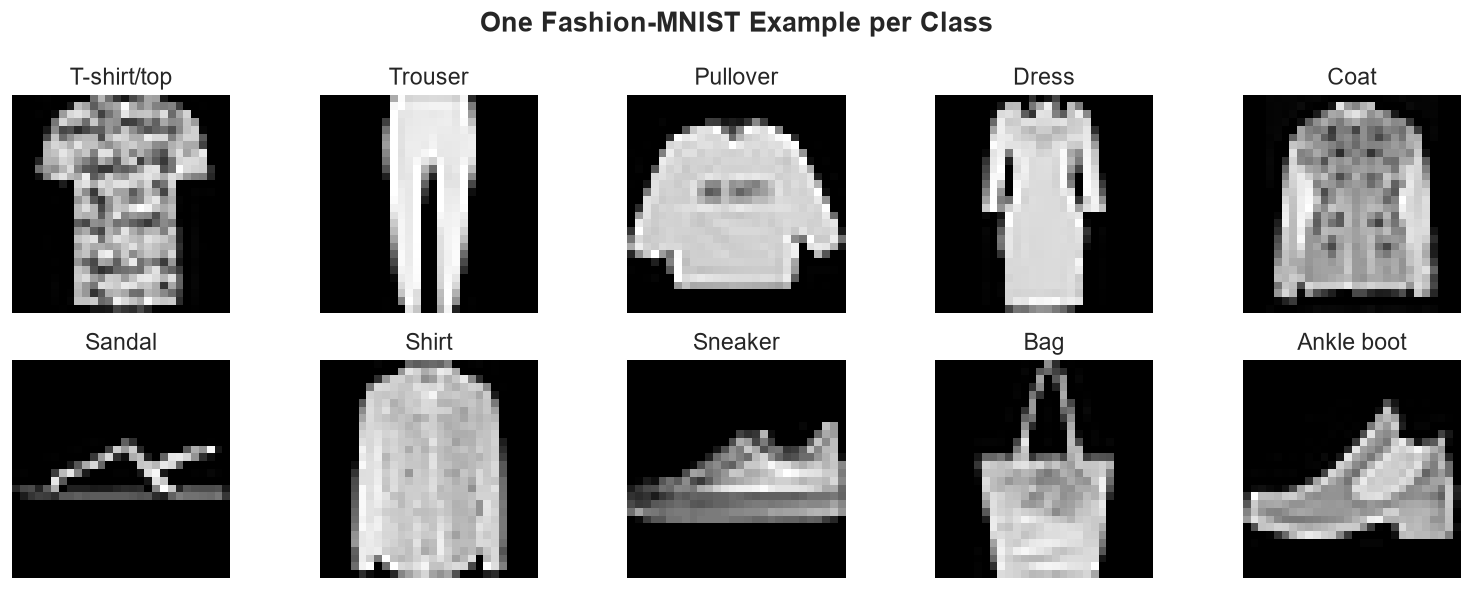

In [35]:
# Visual check: one example from each class
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for label, ax in zip(CLASS_NAMES.keys(), axes.flat):
    sample_row = train_df.loc[train_df["label"] == label].iloc[0]
    ax.imshow(row_to_image(sample_row), cmap="gray")
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
fig.suptitle("One Fashion-MNIST Example per Class", fontsize=16, fontweight="bold")
fig.tight_layout()

In [36]:
# Save the class-example grid
fig.savefig(IMAGES_DIR / "01_examples_by_class.png", bbox_inches="tight")
fig.savefig(IMAGES_DIR / "01_examples_by_class.svg", bbox_inches="tight")
plt.show()

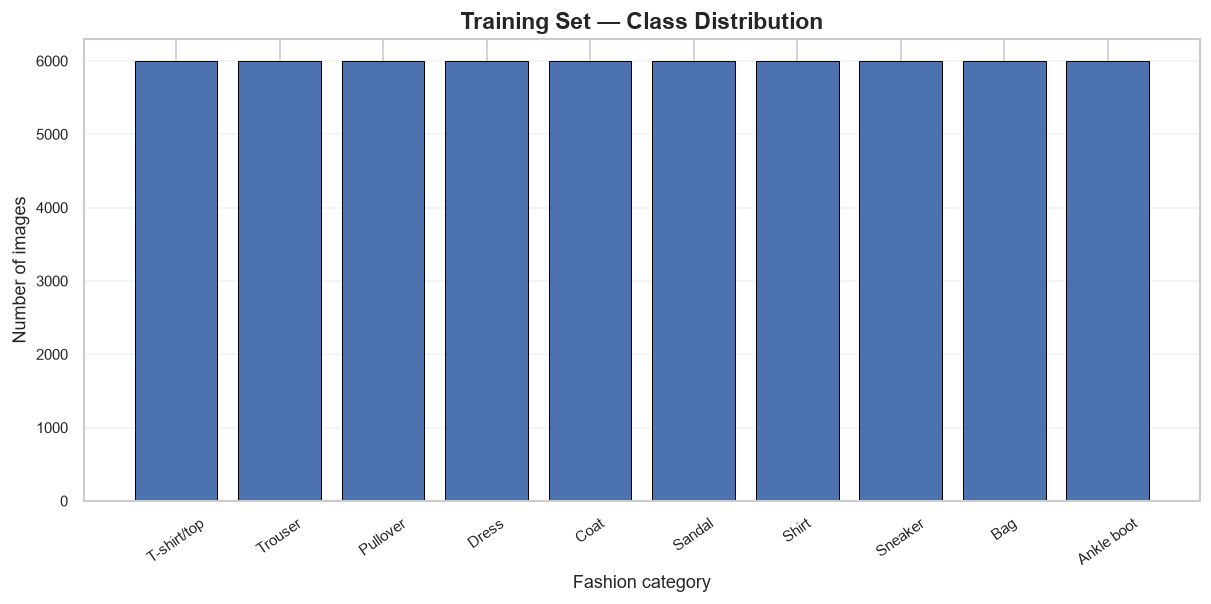

In [37]:
# Matplotlib class distribution
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(class_counts["class_name"], class_counts["count"], edgecolor="black", linewidth=0.6)
ax.set_title("Training Set — Class Distribution", fontweight="bold")
ax.set_xlabel("Fashion category")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)

In [38]:
# Save the Matplotlib class distribution
fig.savefig(IMAGES_DIR / "02_class_distribution_matplotlib.png", bbox_inches="tight")
plt.show()

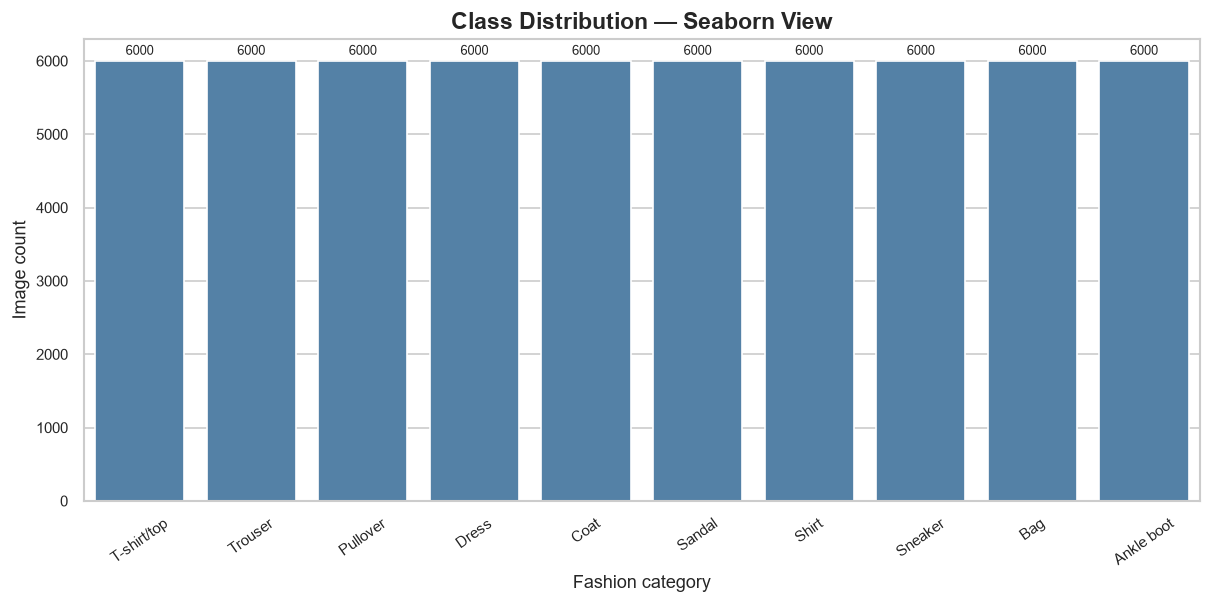

In [39]:
# Seaborn class distribution with count annotations
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=class_counts, x="class_name", y="count", color="steelblue", ax=ax)
ax.set_title("Class Distribution — Seaborn View", fontweight="bold")
ax.set_xlabel("Fashion category")
ax.set_ylabel("Image count")
ax.tick_params(axis="x", rotation=35)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=2, fontsize=8)

In [40]:
# Save the Seaborn class distribution
fig.savefig(IMAGES_DIR / "03_class_distribution_seaborn.png", bbox_inches="tight")
plt.show()

In [41]:
# Interactive Plotly class distribution
fig_class_plotly = px.bar(
    class_counts, x="class_name", y="count", color="class_name",
    text="count", title="Interactive Fashion-MNIST Class Distribution",
    labels={"class_name": "Fashion category", "count": "Number of images"}
)
fig_class_plotly.update_layout(showlegend=False, template="plotly_white", xaxis_tickangle=-30)
fig_class_plotly.show()

In [42]:
# Export the interactive class distribution
fig_class_plotly.write_html(IMAGES_DIR / "04_class_distribution_interactive.html", include_plotlyjs="cdn")

In [43]:
# Pixel intensity sample for efficient visualization (avoids plotting every cell)
train_pixels_sample = train_df[PIXEL_COLUMNS].to_numpy(dtype=np.uint8)[::500].ravel()
print("Sampled pixel observations:", len(train_pixels_sample))

Sampled pixel observations: 94080


Text(0, 0.5, 'Frequency')

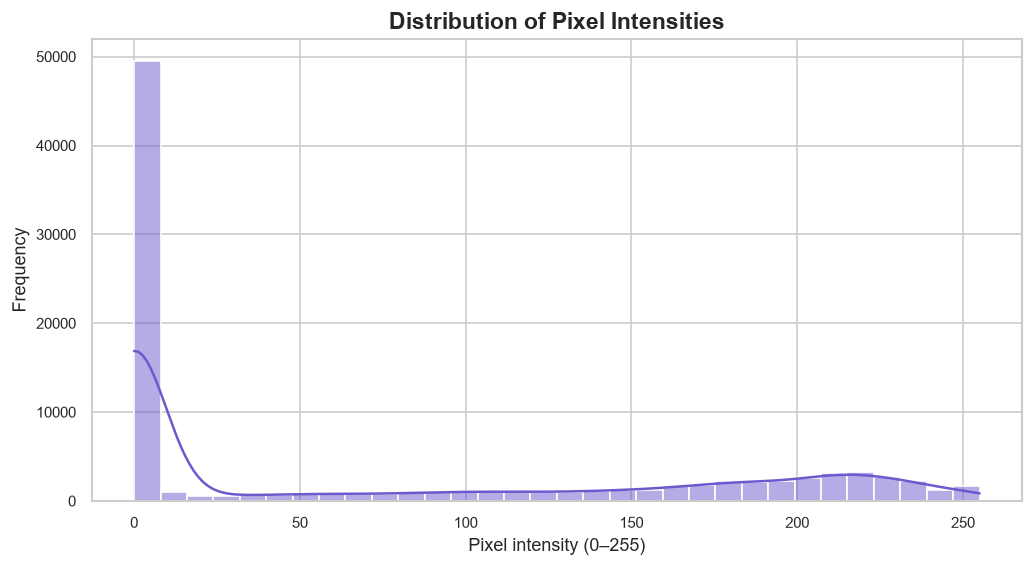

In [44]:
# Pixel intensity distribution
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(train_pixels_sample, bins=32, kde=True, ax=ax, color="slateblue")
ax.set_title("Distribution of Pixel Intensities", fontweight="bold")
ax.set_xlabel("Pixel intensity (0–255)")
ax.set_ylabel("Frequency")

In [45]:
# Save pixel intensity distribution
fig.savefig(IMAGES_DIR / "05_pixel_intensity_distribution.png", bbox_inches="tight")
plt.show()

In [46]:
# Compute class-wise mean images
mean_images = {}
for label in CLASS_NAMES:
    class_pixels = train_df.loc[train_df["label"] == label, PIXEL_COLUMNS].to_numpy(dtype=np.float32)
    mean_images[label] = class_pixels.mean(axis=0).reshape(IMAGE_SIZE, IMAGE_SIZE)

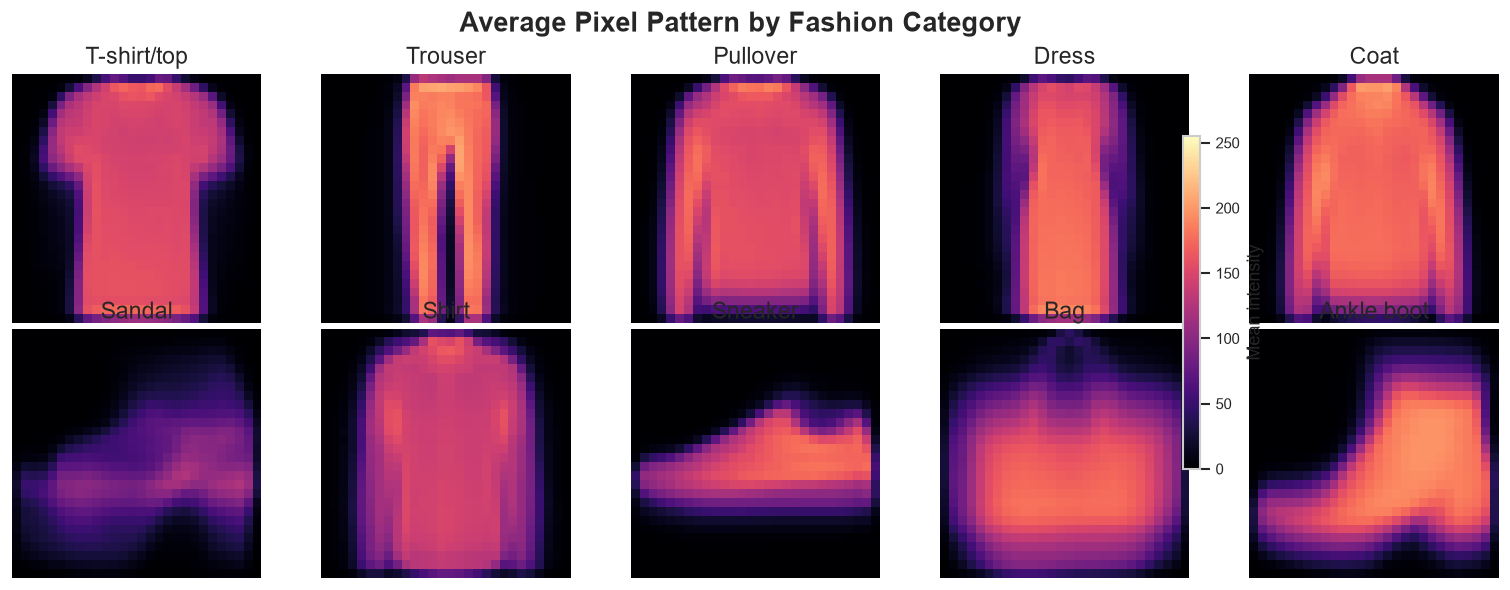

In [47]:
# Display the mean image for each class
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for label, ax in zip(CLASS_NAMES.keys(), axes.flat):
    image_artist = ax.imshow(mean_images[label], cmap="magma", vmin=0, vmax=255)
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
fig.suptitle("Average Pixel Pattern by Fashion Category", fontsize=16, fontweight="bold")
fig.colorbar(image_artist, ax=axes.ravel().tolist(), shrink=0.72, label="Mean intensity")
fig.tight_layout()

In [48]:
# Save class mean images
fig.savefig(IMAGES_DIR / "06_class_mean_images.png", bbox_inches="tight")
plt.show()

In [49]:
# Overall mean and standard-deviation pixel maps
all_train_pixels = train_df[PIXEL_COLUMNS].to_numpy(dtype=np.uint8)
mean_pixel_map = all_train_pixels.mean(axis=0).reshape(IMAGE_SIZE, IMAGE_SIZE)
std_pixel_map = all_train_pixels.std(axis=0).reshape(IMAGE_SIZE, IMAGE_SIZE)
print("Mean pixel intensity:", round(float(all_train_pixels.mean()), 3))
print("Std. pixel intensity:", round(float(all_train_pixels.std()), 3))

Mean pixel intensity: 72.957
Std. pixel intensity: 89.967


Text(68.34326171875, 0.5, 'Pixel row')

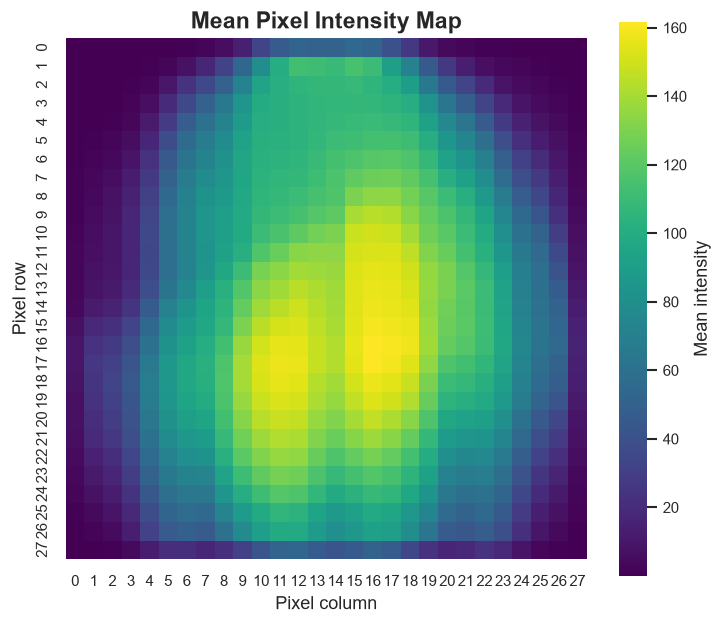

In [50]:
# Seaborn heatmap: overall mean pixel intensity
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(mean_pixel_map, cmap="viridis", square=True, cbar_kws={"label": "Mean intensity"}, ax=ax)
ax.set_title("Mean Pixel Intensity Map", fontweight="bold")
ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")

In [51]:
# Save mean intensity heatmap
fig.savefig(IMAGES_DIR / "07_mean_pixel_heatmap.png", bbox_inches="tight")
plt.show()

Text(68.34326171875, 0.5, 'Pixel row')

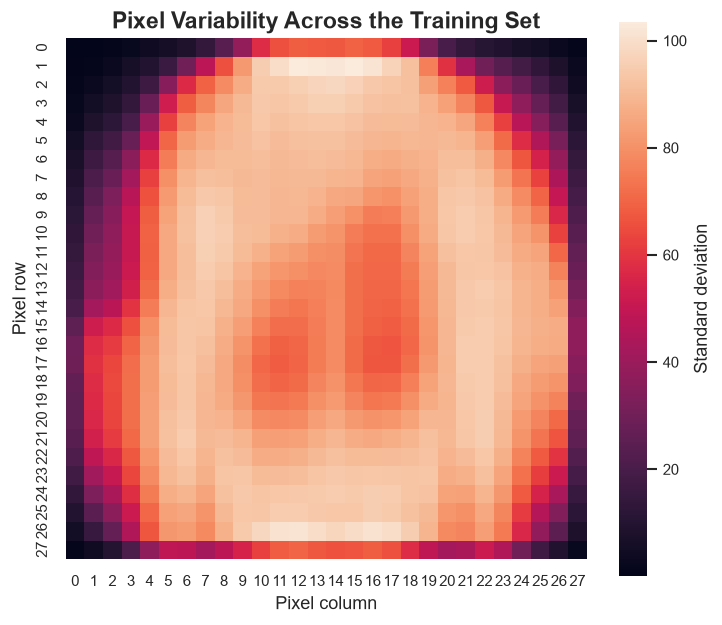

In [52]:
# Seaborn heatmap: pixel variability
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(std_pixel_map, cmap="rocket", square=True, cbar_kws={"label": "Standard deviation"}, ax=ax)
ax.set_title("Pixel Variability Across the Training Set", fontweight="bold")
ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")

In [53]:
# Save standard-deviation heatmap
fig.savefig(IMAGES_DIR / "08_pixel_standard_deviation_heatmap.png", bbox_inches="tight")
plt.show()

In [54]:
# Mean image brightness by class
class_brightness = pd.DataFrame({
    "label": list(CLASS_NAMES.keys()),
    "class_name": [CLASS_NAMES[k] for k in CLASS_NAMES],
    "mean_intensity": [float(mean_images[k].mean()) for k in CLASS_NAMES],
})
display(class_brightness.sort_values("mean_intensity", ascending=False))

,label,class_name,mean_intensity
4,4,Coat,98.155655
2,2,Pullover,95.719330
8,8,Bag,90.035751
6,6,Shirt,85.115097
0,0,T-shirt/top,82.879265
9,9,Ankle boot,77.007149
3,3,Dress,66.201492
1,1,Trouser,56.748375
7,7,Sneaker,42.835667
5,5,Sandal,34.870514


In [55]:
# Plotly comparison of average brightness across classes
fig_brightness = px.bar(
    class_brightness.sort_values("mean_intensity", ascending=False),
    x="class_name", y="mean_intensity", color="mean_intensity",
    title="Average Image Brightness by Class",
    labels={"class_name": "Fashion category", "mean_intensity": "Mean pixel intensity"},
    color_continuous_scale="Viridis"
)
fig_brightness.update_layout(template="plotly_white", xaxis_tickangle=-30)
fig_brightness.show()

In [56]:
# Export interactive brightness comparison
fig_brightness.write_html(IMAGES_DIR / "09_class_brightness_interactive.html", include_plotlyjs="cdn")

In [57]:
# Save the EDA summary tables
class_counts.to_csv(ARTIFACTS_DIR / "class_distribution.csv", index=False)
class_brightness.to_csv(ARTIFACTS_DIR / "class_brightness.csv", index=False)
pd.DataFrame([quality_report]).to_json(ARTIFACTS_DIR / "data_quality_report.json", orient="records", indent=2)
print("EDA tables exported.")

EDA tables exported.


## 4. Preprocessing and PyTorch data pipeline

In [58]:
# Extract features and labels separately from both CSV files
X_all = train_df[PIXEL_COLUMNS].to_numpy(dtype=np.uint8)
y_all = train_df[TARGET_COLUMN].to_numpy(dtype=np.int64)
X_test_raw = test_df[PIXEL_COLUMNS].to_numpy(dtype=np.uint8)
y_test = test_df[TARGET_COLUMN].to_numpy(dtype=np.int64)
print("Train source arrays:", X_all.shape, y_all.shape)
print("Test arrays:", X_test_raw.shape, y_test.shape)

Train source arrays: (60000, 784) (60000,)
Test arrays: (10000, 784) (10000,)


In [59]:
# Stratified split: keep each class proportion similar in train and validation
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_all, y_all, test_size=VALIDATION_SIZE, random_state=RANDOM_SEED, stratify=y_all
)
print("Train split:", X_train_raw.shape, y_train.shape)
print("Validation split:", X_val_raw.shape, y_val.shape)

Train split: (51000, 784) (51000,)
Validation split: (9000, 784) (9000,)


In [60]:
# Normalize grayscale values to [0, 1]
X_train = X_train_raw.astype(np.float32) / 255.0
X_val = X_val_raw.astype(np.float32) / 255.0
X_test = X_test_raw.astype(np.float32) / 255.0
print("Normalized range:", float(X_train.min()), "to", float(X_train.max()))
del X_all, X_train_raw, X_val_raw, X_test_raw
import gc
gc.collect()

Normalized range: 0.0 to 1.0


26332

In [61]:
# Confirm that normalization did not alter labels or sample counts
assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)
assert X_test.shape[0] == len(y_test)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()
print("Preprocessing checks passed.")

Preprocessing checks passed.


In [62]:
# Re-check class proportions after stratified splitting
split_balance = pd.DataFrame({
    "Train": pd.Series(y_train).value_counts(normalize=True),
    "Validation": pd.Series(y_val).value_counts(normalize=True),
    "Test": pd.Series(y_test).value_counts(normalize=True),
}).sort_index()
split_balance.index = [CLASS_NAMES[int(i)] for i in split_balance.index]
display((100 * split_balance).round(2))

,Train,Validation,Test
T-shirt/top,10.0,10.0,10.0
Trouser,10.0,10.0,10.0
Pullover,10.0,10.0,10.0
Dress,10.0,10.0,10.0
Coat,10.0,10.0,10.0
Sandal,10.0,10.0,10.0
Shirt,10.0,10.0,10.0
Sneaker,10.0,10.0,10.0
Bag,10.0,10.0,10.0
Ankle boot,10.0,10.0,10.0


In [63]:
# Dataset wrapper for flattened 28 x 28 images
class FashionDataset(Dataset):
    def __init__(self, features: np.ndarray, labels: np.ndarray):
        self.features = torch.as_tensor(features, dtype=torch.float32)
        self.labels = torch.as_tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]

In [64]:
# Create independent dataset objects
train_dataset = FashionDataset(X_train, y_train)
val_dataset = FashionDataset(X_val, y_val)
test_dataset = FashionDataset(X_test, y_test)
print("Dataset lengths:", len(train_dataset), len(val_dataset), len(test_dataset))

Dataset lengths: 51000 9000 10000


In [65]:
# Configure reproducible shuffling for the training DataLoader
loader_generator = torch.Generator()
loader_generator.manual_seed(RANDOM_SEED)

In [66]:
# DataLoader performance settings
loader_common = {
    "num_workers": NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
    "persistent_workers": NUM_WORKERS > 0,
}

In [67]:
# Build loaders; only training data is shuffled
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=loader_generator, **loader_common
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_common
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_common
)
print("Batches — train/validation/test:", len(train_loader), len(val_loader), len(test_loader))

Batches — train/validation/test: 200 36 40


In [68]:
# Inspect a real batch from the training loader
batch_features, batch_labels = next(iter(train_loader))
print("Batch feature shape:", tuple(batch_features.shape))
print("Batch label shape:", tuple(batch_labels.shape))
print("Batch dtype:", batch_features.dtype, batch_labels.dtype)

Batch feature shape: (256, 784)
Batch label shape: (256,)
Batch dtype: torch.float32 torch.int64


In [69]:
# Verify that the model input is flattened and normalized
assert batch_features.shape[1] == INPUT_DIM
assert batch_features.min().item() >= 0.0
assert batch_features.max().item() <= 1.0
print("PyTorch batch validation passed.")

PyTorch batch validation passed.


## 5. ANN architecture and reusable training utilities

In [70]:
# Configurable fully connected neural network; Optuna selects activation and architecture
class FashionANN(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, hidden_dims=(512, 256),
                 num_classes=NUM_CLASSES, dropout=0.25, activation="ReLU"):
        super().__init__()
        activation_key = str(activation).lower().replace("_", "").replace("-", "")
        activation_layers = {
            "relu": lambda: nn.ReLU(inplace=True),
            "gelu": nn.GELU,
            "leakyrelu": lambda: nn.LeakyReLU(negative_slope=0.1, inplace=True),
        }
        if activation_key not in activation_layers:
            raise ValueError(f"Unsupported activation: {activation}")

        layers = []
        previous_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(previous_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                activation_layers[activation_key](),
                nn.Dropout(dropout),
            ])
            previous_dim = hidden_dim
        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)
        self.activation_name = activation

    def forward(self, x):
        return self.network(x)

In [71]:
# Reference configuration only; the final configuration is selected by Optuna
DEFAULT_CONFIG = {
    "hidden_dims": [512, 256],
    "dropout": DROPOUT_RATE,
    "activation": "ReLU",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "momentum": 0.9,
}
print("Reference ANN configuration ready; Optuna will determine the final settings.")

Reference ANN configuration ready; Optuna will determine the final settings.


In [72]:
# Instantiate an optimizer from the configuration selected by Optuna

def build_optimizer(model, config):
    name = str(config.get("optimizer", "AdamW")).lower()
    lr = float(config.get("learning_rate", LEARNING_RATE))
    weight_decay = float(config.get("weight_decay", WEIGHT_DECAY))
    if name == "adam":
        return optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    if name == "sgd":
        momentum = float(config.get("momentum", 0.9))
        return optim.SGD(model.parameters(), lr=lr, momentum=momentum,
                         weight_decay=weight_decay, nesterov=True)
    return optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

In [73]:
# Helper: one complete training epoch
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for features, labels in loader:
        features = features.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(features)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

In [74]:
# Helper: evaluate one loader without gradient tracking
def evaluate_model(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.inference_mode():
        for features, labels in loader:
            features = features.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(features)
            loss = criterion(logits, labels)
            running_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, correct / total

In [75]:
# Full training routine with best-checkpoint tracking and early stopping
def fit_model(model, train_dl, val_dl, config, epochs=NUM_EPOCHS, patience=EARLY_STOPPING_PATIENCE):
    criterion = nn.CrossEntropyLoss()
    optimizer = build_optimizer(model, config)
    history = []
    best_val_loss = float("inf")
    best_state = deepcopy(model.state_dict())
    epochs_without_improvement = 0
    start_time = time.perf_counter()
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_dl, criterion, optimizer)
        val_loss, val_acc = evaluate_model(model, val_dl, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_accuracy": train_acc,
                        "val_loss": val_loss, "val_accuracy": val_acc})
        print(f"Epoch {epoch:02d}/{epochs} | train loss {train_loss:.4f} | train acc {train_acc:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping triggered at epoch {epoch}.")
            break
    model.load_state_dict(best_state)
    elapsed = time.perf_counter() - start_time
    return model, pd.DataFrame(history), elapsed

In [76]:
# Architecture parameter count helper
def count_trainable_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

In [77]:
# Build a reference model to inspect the network before tuning
preview_model = FashionANN(
    hidden_dims=tuple(DEFAULT_CONFIG["hidden_dims"]),
    dropout=DEFAULT_CONFIG["dropout"],
    activation=DEFAULT_CONFIG["activation"],
).to(device)
print(preview_model)

FashionANN(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [78]:
# Record model complexity
model_parameter_count = count_trainable_parameters(preview_model)
print(f"Trainable parameters: {model_parameter_count:,}")

Trainable parameters: 537,354


In [79]:
# Check model tensor dimensions with a sample batch
preview_model.eval()
with torch.inference_mode():
    preview_logits = preview_model(batch_features[:8].to(device))
print("Logit shape:", tuple(preview_logits.shape))
assert preview_logits.shape == (8, NUM_CLASSES)

Logit shape: (8, 10)


## 6. Optuna hyperparameter optimization — the core experiment

Optuna searches for a high-performing ANN configuration using **validation accuracy** as the objective. The search uses a seeded Tree-structured Parzen Estimator (TPE) sampler and a MedianPruner to stop weak trials early.

**Hyperparameters explored:** number of hidden layers, layer width, activation function, dropout, optimizer, learning rate, weight decay, batch size, and SGD momentum when SGD is selected.

The study is persisted in `artifacts/` so trial history can be inspected and the experiment can be resumed. The best configuration is exported and passed directly into final model training. The held-out test set is never used during tuning.

In [80]:
# Optuna is a required dependency for this project; install it automatically if missing
import importlib.util
import subprocess

if importlib.util.find_spec("optuna") is None:
    print("Optuna is not installed. Installing the required tuning dependency...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "optuna"])

import optuna
print("Optuna version:", optuna.__version__)
print("Optuna is ready for the hyperparameter search.")

Optuna is not installed. Installing the required tuning dependency...
Optuna version: 5.0.0
Optuna is ready for the hyperparameter search.


In [81]:
# Define the Optuna search space across architecture and optimization settings

def sample_optuna_config(trial):
    n_layers = trial.suggest_int("num_hidden_layers", 1, 3)
    first_width = trial.suggest_categorical("first_layer_width", [256, 384, 512, 768])
    hidden_dims = [max(64, first_width // (2 ** layer)) for layer in range(n_layers)]
    optimizer_name = trial.suggest_categorical("optimizer", ["AdamW", "Adam", "SGD"])

    config = {
        "hidden_dims": hidden_dims,
        "dropout": trial.suggest_float("dropout", 0.05, 0.50),
        "activation": trial.suggest_categorical("activation", ["ReLU", "GELU", "LeakyReLU"]),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-7, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
        "optimizer": optimizer_name,
        "momentum": 0.9,
    }
    if optimizer_name == "SGD":
        config["momentum"] = trial.suggest_float("sgd_momentum", 0.80, 0.99)
    return config

In [82]:
# Optuna objective: maximize the best validation accuracy achieved during a trial
# The external test set is intentionally not referenced anywhere in this function.

def optuna_objective(trial):
    set_global_seed(RANDOM_SEED + trial.number)
    trial_config = sample_optuna_config(trial)
    trial_generator = torch.Generator().manual_seed(RANDOM_SEED + trial.number)
    trial_train_loader = DataLoader(
        train_dataset,
        batch_size=int(trial_config["batch_size"]),
        shuffle=True,
        generator=trial_generator,
        **loader_common,
    )
    trial_val_loader = DataLoader(
        val_dataset,
        batch_size=int(trial_config["batch_size"]),
        shuffle=False,
        **loader_common,
    )

    trial_model = FashionANN(
        hidden_dims=tuple(trial_config["hidden_dims"]),
        dropout=float(trial_config["dropout"]),
        activation=trial_config["activation"],
    ).to(device)
    trial_optimizer = build_optimizer(trial_model, trial_config)
    criterion = nn.CrossEntropyLoss()
    best_accuracy = 0.0
    best_loss = float("inf")
    best_epoch = 0

    try:
        for epoch in range(1, OPTUNA_EPOCHS + 1):
            train_loss, train_accuracy = train_one_epoch(
                trial_model, trial_train_loader, criterion, trial_optimizer
            )
            val_loss, val_accuracy = evaluate_model(
                trial_model, trial_val_loader, criterion
            )

            if (val_accuracy > best_accuracy) or (
                np.isclose(val_accuracy, best_accuracy) and val_loss < best_loss
            ):
                best_accuracy = float(val_accuracy)
                best_loss = float(val_loss)
                best_epoch = epoch

            trial.report(float(val_accuracy), step=epoch)
            trial.set_user_attr("best_epoch", int(best_epoch))
            trial.set_user_attr("best_validation_loss", float(best_loss))
            trial.set_user_attr("hidden_dims", trial_config["hidden_dims"])
            if trial.should_prune():
                raise optuna.TrialPruned()

        return best_accuracy
    finally:
        del trial_model, trial_optimizer, trial_train_loader, trial_val_loader
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

In [83]:
# Run the mandatory Optuna study and select its best completed trial
OPTUNA_DB_PATH = ARTIFACTS_DIR / "fashion_mnist_optuna.db"
OPTUNA_STORAGE = f"sqlite:///{OPTUNA_DB_PATH.resolve().as_posix()}"

study = optuna.create_study(
    direction="maximize",
    study_name=OPTUNA_STUDY_NAME,
    storage=OPTUNA_STORAGE,
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
)
trials_before_search = len(study.trials)
study.optimize(
    optuna_objective,
    n_trials=OPTUNA_TRIALS,
    timeout=OPTUNA_TIMEOUT,
    show_progress_bar=True,
    gc_after_trial=True,
)

completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
pruned_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED]
if not completed_trials:
    raise RuntimeError("Optuna did not complete a trial. Review the trial errors before continuing.")

best_trial = study.best_trial
best_params = best_trial.params
n_layers = int(best_params["num_hidden_layers"])
first_width = int(best_params["first_layer_width"])
best_config = {
    "hidden_dims": [max(64, first_width // (2 ** layer)) for layer in range(n_layers)],
    "dropout": float(best_params["dropout"]),
    "activation": best_params["activation"],
    "learning_rate": float(best_params["learning_rate"]),
    "weight_decay": float(best_params["weight_decay"]),
    "batch_size": int(best_params["batch_size"]),
    "optimizer": best_params["optimizer"],
    "momentum": float(best_params.get("sgd_momentum", 0.9)),
}

print(f"New trials run: {len(study.trials) - trials_before_search}")
print(f"Completed trials: {len(completed_trials)} | Pruned trials: {len(pruned_trials)}")
print(f"Best trial: #{best_trial.number}")
print(f"Best validation accuracy: {study.best_value:.4%}")
print("Optuna-selected configuration:", best_config)

[I 2026-10-26 20:52:27,395] A new study created in RDB with name: fashion_mnist_ann_tuning


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-10-26 20:52:40,955] Trial 0 finished with value: 0.8563333333333333 and parameters: {'num_hidden_layers': 2, 'first_layer_width': 256, 'optimizer': 'SGD', 'dropout': 0.32050175528444397, 'activation': 'LeakyReLU', 'learning_rate': 0.004622589001020831, 'weight_decay': 7.068974950624599e-07, 'batch_size': 512, 'sgd_momentum': 0.8997037220101252}. Best is trial 0 with value: 0.8563333333333333.
[I 2026-10-26 20:52:54,282] Trial 1 finished with value: 0.8665555555555555 and parameters: {'num_hidden_layers': 2, 'first_layer_width': 384, 'optimizer': 'SGD', 'dropout': 0.1398532019712619, 'activation': 'GELU', 'learning_rate': 0.0016409286730647919, 'weight_decay': 4.809461967501569e-07, 'batch_size': 512, 'sgd_momentum': 0.9535954961421276}. Best is trial 1 with value: 0.8665555555555555.
[I 2026-10-26 20:53:08,965] Trial 2 finished with value: 0.8797777777777778 and parameters: {'num_hidden_layers': 1, 'first_layer_width': 384, 'optimizer': 'SGD', 'dropout': 0.1664509917200076, 'ac

In [84]:
# Export Optuna trial history, readable summary, and best hyperparameters
trial_frame = study.trials_dataframe(
    attrs=("number", "value", "params", "state", "user_attrs", "duration")
)
trial_frame.to_csv(ARTIFACTS_DIR / "optuna_trials.csv", index=False)

trial_summary_rows = []
for trial in study.trials:
    duration = trial.duration.total_seconds() if trial.duration is not None else np.nan
    trial_summary_rows.append({
        "trial": trial.number,
        "state": trial.state.name,
        "validation_accuracy": trial.value,
        "best_epoch": trial.user_attrs.get("best_epoch"),
        "best_validation_loss": trial.user_attrs.get("best_validation_loss"),
        "duration_seconds": duration,
        **{f"param_{key}": value for key, value in trial.params.items()},
    })
pd.DataFrame(trial_summary_rows).to_csv(
    ARTIFACTS_DIR / "optuna_trial_summary.csv", index=False
)

best_export = {
    "objective": "maximize_best_validation_accuracy",
    "best_trial_number": int(best_trial.number),
    "best_validation_accuracy": float(study.best_value),
    "best_trial_validation_loss": best_trial.user_attrs.get("best_validation_loss"),
    "best_configuration": best_config,
    "raw_optuna_parameters": best_params,
}
with open(ARTIFACTS_DIR / "optuna_best_params.json", "w", encoding="utf-8") as file:
    json.dump(best_export, file, indent=2)

print("Optuna exports saved in artifacts/: trial history, trial summary, and best parameters.")

Optuna exports saved in artifacts/: trial history, trial summary, and best parameters.


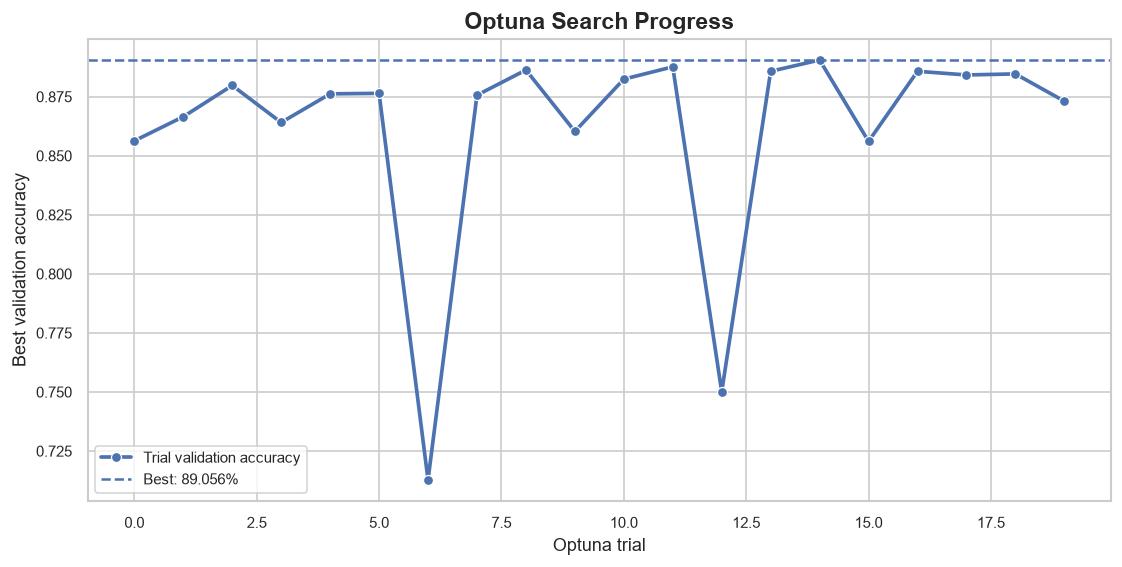

In [85]:
# Plot and export the Optuna optimization history (interactive + static)
from optuna.visualization import plot_optimization_history

optuna_history_fig = plot_optimization_history(study)
optuna_history_fig.update_layout(
    title="Optuna Optimization History — Fashion-MNIST ANN",
    template="plotly_white",
    xaxis_title="Trial",
    yaxis_title="Best validation accuracy",
)
optuna_history_fig.show()
optuna_history_fig.write_html(
    IMAGES_DIR / "10_optuna_optimization_history.html", include_plotlyjs="cdn"
)

completed_frame = pd.DataFrame([
    {"trial": t.number, "validation_accuracy": t.value}
    for t in study.trials if t.value is not None
]).sort_values("trial")
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(
    data=completed_frame, x="trial", y="validation_accuracy",
    marker="o", linewidth=2.2, ax=ax, label="Trial validation accuracy"
)
ax.axhline(study.best_value, linestyle="--", linewidth=1.5,
           label=f"Best: {study.best_value:.3%}")
ax.set_title("Optuna Search Progress", fontweight="bold")
ax.set_xlabel("Optuna trial")
ax.set_ylabel("Best validation accuracy")
ax.legend(frameon=True)
fig.savefig(IMAGES_DIR / "10_optuna_optimization_history.png", bbox_inches="tight")
plt.show()

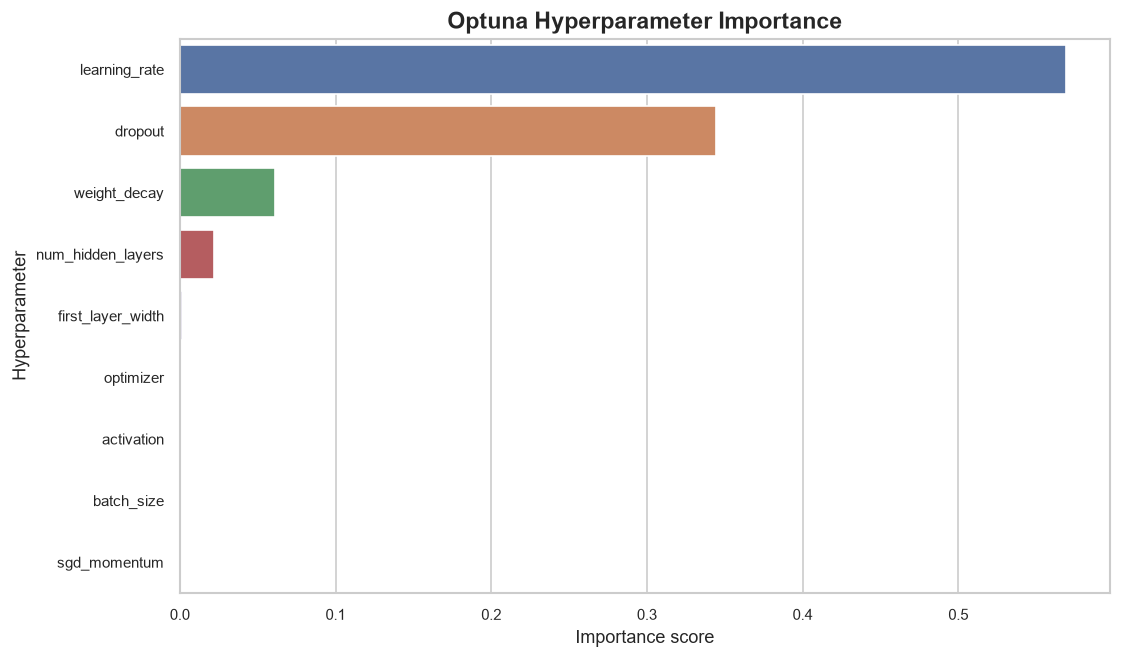

In [86]:
# Analyze and export Optuna hyperparameter importance
from optuna.visualization import plot_param_importances

try:
    parameter_importances = optuna.importance.get_param_importances(study)
    importance_frame = pd.DataFrame({
        "hyperparameter": list(parameter_importances.keys()),
        "importance": list(parameter_importances.values()),
    }).sort_values("importance", ascending=False)
    importance_frame.to_csv(ARTIFACTS_DIR / "optuna_parameter_importance.csv", index=False)

    importance_fig = plot_param_importances(study)
    importance_fig.update_layout(
        title="Which Hyperparameters Matter Most?",
        template="plotly_white",
        xaxis_title="Importance",
        yaxis_title="Hyperparameter",
    )
    importance_fig.show()
    importance_fig.write_html(
        IMAGES_DIR / "11_optuna_parameter_importance.html", include_plotlyjs="cdn"
    )

    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(
        data=importance_frame, x="importance", y="hyperparameter",
        hue="hyperparameter", dodge=False, legend=False, ax=ax
    )
    ax.set_title("Optuna Hyperparameter Importance", fontweight="bold")
    ax.set_xlabel("Importance score")
    ax.set_ylabel("Hyperparameter")
    fig.savefig(IMAGES_DIR / "11_optuna_parameter_importance.png", bbox_inches="tight")
    plt.show()
except Exception as exc:
    print("Parameter importance is not available for this study yet:", type(exc).__name__)
    print("Run more completed Optuna trials to obtain a stable importance estimate.")

## 7. Train the final ANN using Optuna's best configuration

The configuration below comes from `study.best_trial`. The final fit uses the Optuna-selected architecture, activation, optimizer, learning rate, regularization, and batch size. Validation loss controls early stopping; the external test set remains untouched until the final evaluation section.

In [87]:
# Build data loaders using the chosen batch size
final_train_loader = DataLoader(
    train_dataset, batch_size=int(best_config["batch_size"]), shuffle=True,
    generator=torch.Generator().manual_seed(RANDOM_SEED), **loader_common
)
final_val_loader = DataLoader(
    val_dataset, batch_size=int(best_config["batch_size"]), shuffle=False, **loader_common
)
final_test_loader = DataLoader(
    test_dataset, batch_size=int(best_config["batch_size"]), shuffle=False, **loader_common
)

In [88]:
# Initialize the final ANN from the best Optuna trial
final_model = FashionANN(
    hidden_dims=tuple(best_config["hidden_dims"]),
    dropout=float(best_config["dropout"]),
    activation=best_config["activation"],
).to(device)
print(final_model)

FashionANN(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=384, bias=True)
    (1): BatchNorm1d(384, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.06177017309867169, inplace=False)
    (4): Linear(in_features=384, out_features=192, bias=True)
    (5): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): Dropout(p=0.06177017309867169, inplace=False)
    (8): Linear(in_features=192, out_features=96, bias=True)
    (9): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Dropout(p=0.06177017309867169, inplace=False)
    (12): Linear(in_features=96, out_features=10, bias=True)
  )
)


In [89]:
# Inspect final model complexity before training
final_parameter_count = count_trainable_parameters(final_model)
print(f"Final model trainable parameters: {final_parameter_count:,}")

Final model trainable parameters: 396,202


In [90]:
# Train with validation-based early stopping
final_model, history_df, training_seconds = fit_model(
    final_model, final_train_loader, final_val_loader, best_config,
    epochs=NUM_EPOCHS, patience=EARLY_STOPPING_PATIENCE
)
print(f"Training completed in {training_seconds / 60:.2f} minutes.")

Epoch 01/25 | train loss 0.5168 | train acc 0.8305 | val loss 0.3929 | val acc 0.8550
Epoch 02/25 | train loss 0.3556 | train acc 0.8707 | val loss 0.3504 | val acc 0.8703
Epoch 03/25 | train loss 0.3151 | train acc 0.8851 | val loss 0.3527 | val acc 0.8708
Epoch 04/25 | train loss 0.2908 | train acc 0.8934 | val loss 0.3292 | val acc 0.8774
Epoch 05/25 | train loss 0.2686 | train acc 0.9005 | val loss 0.3206 | val acc 0.8829
Epoch 06/25 | train loss 0.2517 | train acc 0.9067 | val loss 0.3121 | val acc 0.8840
Epoch 07/25 | train loss 0.2393 | train acc 0.9101 | val loss 0.2982 | val acc 0.8903
Epoch 08/25 | train loss 0.2245 | train acc 0.9168 | val loss 0.3259 | val acc 0.8841
Epoch 09/25 | train loss 0.2133 | train acc 0.9198 | val loss 0.3018 | val acc 0.8918
Epoch 10/25 | train loss 0.1991 | train acc 0.9255 | val loss 0.3769 | val acc 0.8701
Epoch 11/25 | train loss 0.1916 | train acc 0.9278 | val loss 0.3252 | val acc 0.8862
Epoch 12/25 | train loss 0.1823 | train acc 0.9315 | v

In [91]:
# Preview the epoch-by-epoch training history
display(history_df.round(4))

,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.5168,0.8305,0.3929,0.8550
1,2,0.3556,0.8707,0.3504,0.8703
2,3,0.3151,0.8851,0.3527,0.8708
3,4,0.2908,0.8934,0.3292,0.8774
4,5,0.2686,0.9005,0.3206,0.8829
5,6,0.2517,0.9067,0.3121,0.8840
6,7,0.2393,0.9101,0.2982,0.8903
7,8,0.2245,0.9168,0.3259,0.8841
8,9,0.2133,0.9198,0.3018,0.8918
9,10,0.1991,0.9255,0.3769,0.8701


In [92]:
# Save the training history table
history_df.to_csv(ARTIFACTS_DIR / "training_history.csv", index=False)
print("Training history saved.")

Training history saved.


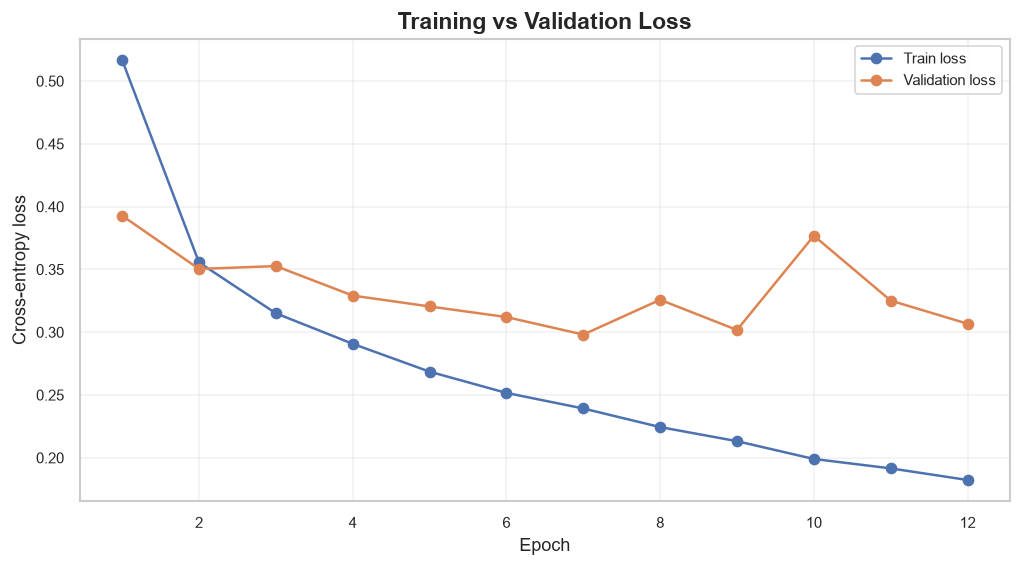

In [93]:
# Plot training and validation loss
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
ax.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
ax.set_title("Training vs Validation Loss", fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.legend()
ax.grid(alpha=0.25)

In [94]:
# Save the loss curve
fig.savefig(IMAGES_DIR / "12_training_validation_loss.png", bbox_inches="tight")
plt.show()

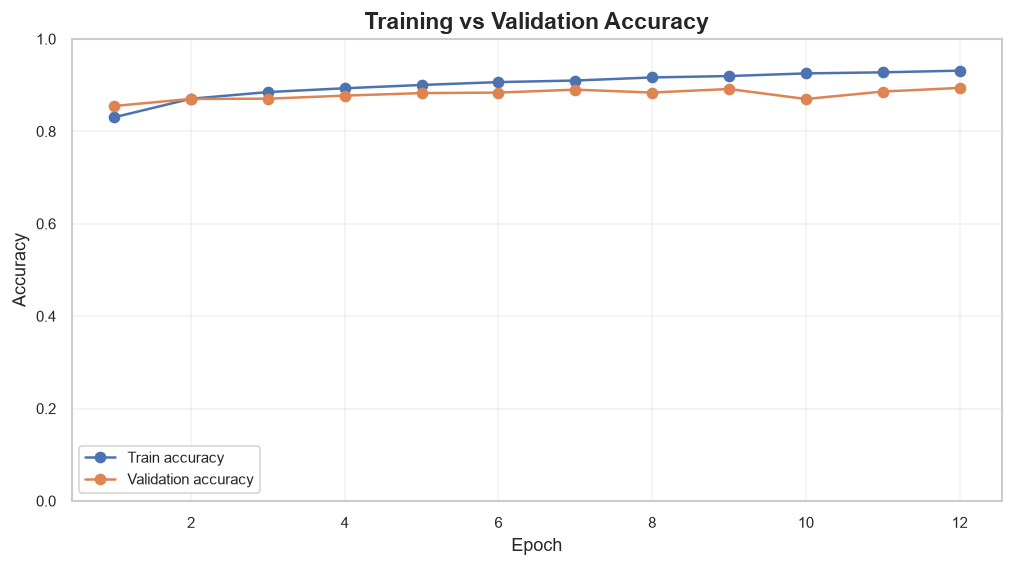

In [95]:
# Plot training and validation accuracy
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_accuracy"], marker="o", label="Train accuracy")
ax.plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation accuracy")
ax.set_title("Training vs Validation Accuracy", fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.25)

In [96]:
# Save the accuracy curve
fig.savefig(IMAGES_DIR / "13_training_validation_accuracy.png", bbox_inches="tight")
plt.show()

In [97]:
# Interactive training history with Plotly
history_long = history_df.melt(id_vars="epoch", value_vars=["train_loss", "val_loss"],
                               var_name="series", value_name="loss")
fig_history = px.line(history_long, x="epoch", y="loss", color="series", markers=True,
                      title="Interactive Training History — Loss")
fig_history.update_layout(template="plotly_white", xaxis_title="Epoch", yaxis_title="Loss")
fig_history.show()

In [98]:
# Export the interactive training history
fig_history.write_html(IMAGES_DIR / "14_training_history_interactive.html", include_plotlyjs="cdn")

In [99]:
# Optional interactive accuracy chart
accuracy_long = history_df.melt(id_vars="epoch", value_vars=["train_accuracy", "val_accuracy"],
                                var_name="series", value_name="accuracy")
fig_accuracy = px.line(accuracy_long, x="epoch", y="accuracy", color="series", markers=True,
                       title="Interactive Training History — Accuracy")
fig_accuracy.update_layout(template="plotly_white", yaxis_range=[0, 1])
fig_accuracy.show()

In [100]:
# Export interactive accuracy chart
fig_accuracy.write_html(IMAGES_DIR / "15_training_accuracy_interactive.html", include_plotlyjs="cdn")

In [101]:
# Summarize convergence and generalization gap
best_epoch_row = history_df.loc[history_df["val_loss"].idxmin()]
training_summary = {
    "epochs_completed": int(len(history_df)),
    "best_epoch": int(best_epoch_row["epoch"]),
    "best_validation_loss": float(best_epoch_row["val_loss"]),
    "validation_accuracy_at_best_loss": float(best_epoch_row["val_accuracy"]),
    "final_train_accuracy": float(history_df.iloc[-1]["train_accuracy"]),
    "final_validation_accuracy": float(history_df.iloc[-1]["val_accuracy"]),
    "training_seconds": float(training_seconds),
}
print(json.dumps(training_summary, indent=2))

{
  "epochs_completed": 12,
  "best_epoch": 7,
  "best_validation_loss": 0.29815148899290295,
  "validation_accuracy_at_best_loss": 0.8903333333333333,
  "final_train_accuracy": 0.9314509803921569,
  "final_validation_accuracy": 0.8941111111111111,
  "training_seconds": 49.22558129997924
}


## 8. Final hold-out test evaluation

In [102]:
# Collect labels, predicted classes, probabilities, and logits in one inference pass
def collect_predictions(model, loader):
    model.eval()
    all_labels, all_logits = [], []
    with torch.inference_mode():
        for features, labels in loader:
            features = features.to(device, non_blocking=True)
            logits = model(features)
            all_labels.append(labels.cpu().numpy())
            all_logits.append(logits.cpu().numpy())
    y_true = np.concatenate(all_labels)
    logits = np.concatenate(all_logits)
    probabilities = torch.softmax(torch.from_numpy(logits), dim=1).numpy()
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities, logits

In [103]:
# Evaluate the untouched test CSV exactly once for final reporting
y_test_true, y_test_pred, y_test_prob, y_test_logits = collect_predictions(final_model, final_test_loader)
print("Predictions collected:", len(y_test_pred))

Predictions collected: 10000


In [104]:
# Core hold-out metrics
test_accuracy = accuracy_score(y_test_true, y_test_pred)
precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_test_true, y_test_pred, average="weighted", zero_division=0
)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_test_true, y_test_pred, average="macro", zero_division=0
)
print(f"Test accuracy: {test_accuracy:.4%}")
print(f"Weighted F1:   {f1_weighted:.4f}")
print(f"Macro F1:      {macro_f1:.4f}")

Test accuracy: 89.6500%
Weighted F1:   0.8951
Macro F1:      0.8951


In [105]:
# Detailed class-wise classification report
report_dict = classification_report(
    y_test_true, y_test_pred, labels=list(CLASS_NAMES.keys()),
    target_names=[CLASS_NAMES[i] for i in CLASS_NAMES],
    output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report_dict).transpose()
display(report_df.round(4))

,precision,recall,f1-score,support
T-shirt/top,0.7940,0.9060,0.8463,1000.0000
Trouser,0.9850,0.9860,0.9855,1000.0000
Pullover,0.8120,0.8640,0.8372,1000.0000
Dress,0.9039,0.9220,0.9129,1000.0000
Coat,0.8625,0.8280,0.8449,1000.0000
Sandal,0.9701,0.9420,0.9559,1000.0000
Shirt,0.8040,0.6440,0.7152,1000.0000
Sneaker,0.9474,0.9190,0.9330,1000.0000
Bag,0.9645,0.9780,0.9712,1000.0000
Ankle boot,0.9225,0.9760,0.9485,1000.0000


In [106]:
# Persist classification report in CSV and JSON formats
report_df.to_csv(ARTIFACTS_DIR / "classification_report.csv")
with open(ARTIFACTS_DIR / "classification_report.json", "w", encoding="utf-8") as file:
    json.dump(report_dict, file, indent=2)

In [107]:
# Consolidated test metrics
test_metrics = {
    "test_accuracy": float(test_accuracy),
    "weighted_precision": float(precision_weighted),
    "weighted_recall": float(recall_weighted),
    "weighted_f1": float(f1_weighted),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "test_samples": int(len(y_test_true)),
    "trainable_parameters": int(final_parameter_count),
}
print(json.dumps(test_metrics, indent=2))

{
  "test_accuracy": 0.8965,
  "weighted_precision": 0.8966050829115142,
  "weighted_recall": 0.8965,
  "weighted_f1": 0.8950527694939696,
  "macro_precision": 0.8966050829115142,
  "macro_recall": 0.8965,
  "macro_f1": 0.8950527694939696,
  "test_samples": 10000,
  "trainable_parameters": 396202
}


In [108]:
# Confusion matrix values and label order
cm = confusion_matrix(y_test_true, y_test_pred, labels=list(CLASS_NAMES.keys()))
class_labels = [CLASS_NAMES[i] for i in CLASS_NAMES]
print("Confusion matrix shape:", cm.shape)

Confusion matrix shape: (10, 10)


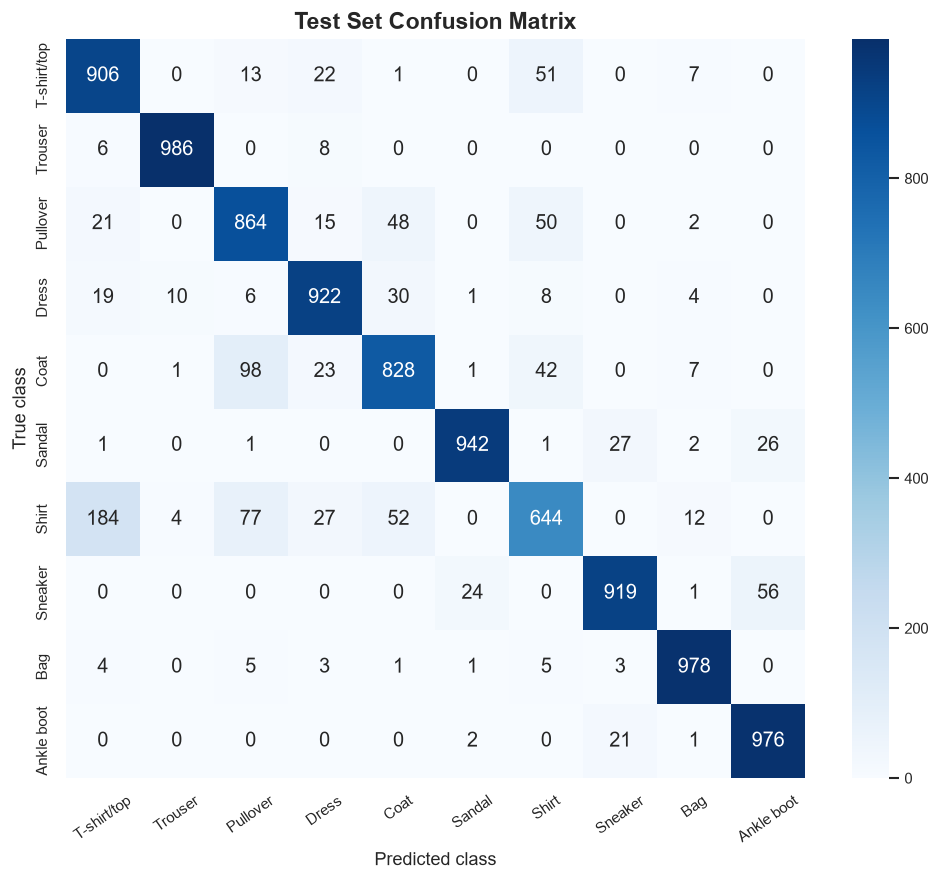

In [109]:
# Confusion matrix heatmap with counts
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", square=True,
            xticklabels=class_labels, yticklabels=class_labels, ax=ax)
ax.set_title("Test Set Confusion Matrix", fontweight="bold")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.tick_params(axis="x", rotation=35)

In [110]:
# Save the confusion matrix heatmap
fig.savefig(IMAGES_DIR / "16_confusion_matrix.png", bbox_inches="tight")
plt.show()

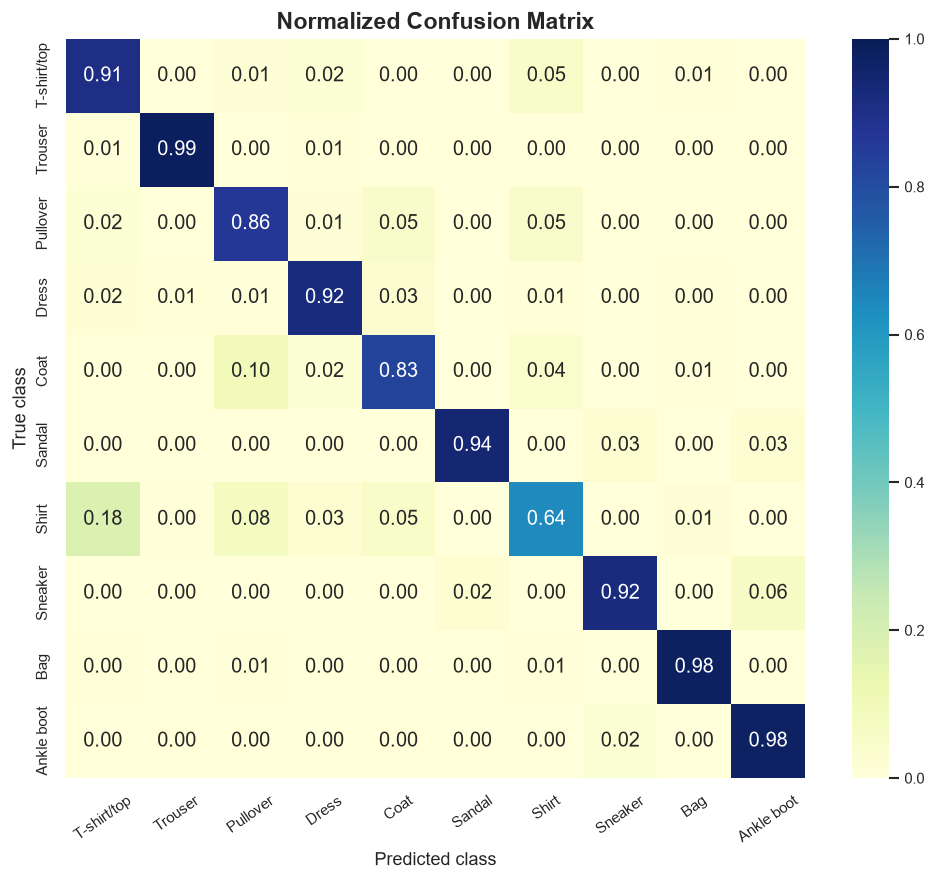

In [111]:
# Normalized confusion matrix highlights per-class recall
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1,
            square=True, xticklabels=class_labels, yticklabels=class_labels, ax=ax)
ax.set_title("Normalized Confusion Matrix", fontweight="bold")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.tick_params(axis="x", rotation=35)

In [112]:
# Save normalized confusion matrix
fig.savefig(IMAGES_DIR / "17_confusion_matrix_normalized.png", bbox_inches="tight")
plt.show()

In [113]:
# Export confusion matrices as labelled tables
pd.DataFrame(cm, index=class_labels, columns=class_labels).to_csv(ARTIFACTS_DIR / "confusion_matrix_counts.csv")
pd.DataFrame(cm_normalized, index=class_labels, columns=class_labels).to_csv(ARTIFACTS_DIR / "confusion_matrix_normalized.csv")

In [114]:
# Per-class precision, recall, and F1 table
per_class_precision, per_class_recall, per_class_f1, per_class_support = precision_recall_fscore_support(
    y_test_true, y_test_pred, labels=list(CLASS_NAMES.keys()), zero_division=0
)
per_class_metrics = pd.DataFrame({
    "class_id": list(CLASS_NAMES.keys()), "class_name": class_labels,
    "precision": per_class_precision, "recall": per_class_recall,
    "f1_score": per_class_f1, "support": per_class_support,
})
display(per_class_metrics.round(4))

,class_id,class_name,precision,recall,f1_score,support
0,0,T-shirt/top,0.7940,0.906,0.8463,1000
1,1,Trouser,0.9850,0.986,0.9855,1000
2,2,Pullover,0.8120,0.864,0.8372,1000
3,3,Dress,0.9039,0.922,0.9129,1000
4,4,Coat,0.8625,0.828,0.8449,1000
5,5,Sandal,0.9701,0.942,0.9559,1000
6,6,Shirt,0.8040,0.644,0.7152,1000
7,7,Sneaker,0.9474,0.919,0.9330,1000
8,8,Bag,0.9645,0.978,0.9712,1000
9,9,Ankle boot,0.9225,0.976,0.9485,1000


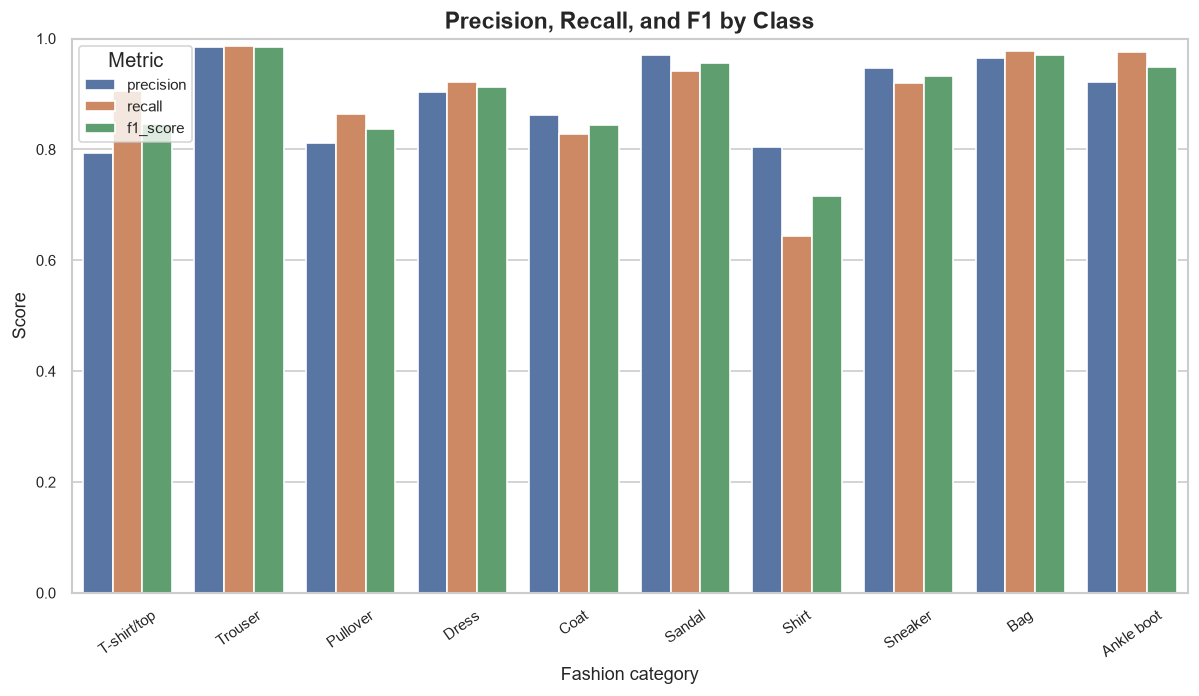

In [115]:
# Visual comparison of class-level scores
metrics_long = per_class_metrics.melt(
    id_vars="class_name", value_vars=["precision", "recall", "f1_score"],
    var_name="metric", value_name="score"
)
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=metrics_long, x="class_name", y="score", hue="metric", palette="deep", ax=ax)
ax.set_title("Precision, Recall, and F1 by Class", fontweight="bold")
ax.set_xlabel("Fashion category")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Metric")

In [116]:
# Save class-level score chart
fig.savefig(IMAGES_DIR / "18_classification_metrics_by_class.png", bbox_inches="tight")
plt.show()

In [117]:
# Interactive class-level scores using Plotly
fig_metrics = px.bar(
    metrics_long, x="class_name", y="score", color="metric", barmode="group",
    title="Interactive Per-Class Classification Metrics",
    labels={"class_name": "Fashion category", "score": "Score", "metric": "Metric"}
)
fig_metrics.update_layout(template="plotly_white", yaxis_range=[0, 1], xaxis_tickangle=-30)
fig_metrics.show()

In [118]:
# Export interactive classification metrics
fig_metrics.write_html(IMAGES_DIR / "19_classification_metrics_interactive.html", include_plotlyjs="cdn")

In [119]:
# Confidence values and correctness flags
max_confidence = y_test_prob.max(axis=1)
prediction_correct = y_test_pred == y_test_true
confidence_df = pd.DataFrame({
    "true_label": y_test_true, "predicted_label": y_test_pred,
    "true_class": [CLASS_NAMES[int(i)] for i in y_test_true],
    "predicted_class": [CLASS_NAMES[int(i)] for i in y_test_pred],
    "confidence": max_confidence, "correct": prediction_correct,
})
display(confidence_df.head())

,true_label,predicted_label,true_class,predicted_class,confidence,correct
0,0,0,T-shirt/top,T-shirt/top,0.955736,True
1,1,1,Trouser,Trouser,0.999970,True
2,2,2,Pullover,Pullover,0.630021,True
3,2,2,Pullover,Pullover,0.557107,True
4,3,3,Dress,Dress,0.605385,True


Text(0, 0.5, 'Density')

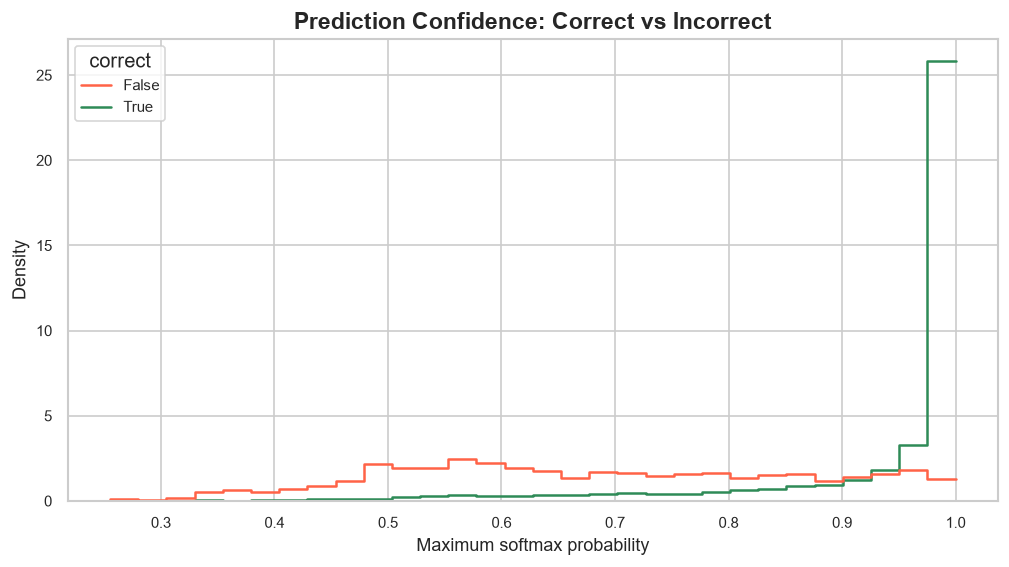

In [120]:
# Confidence distribution for correct and incorrect predictions
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=confidence_df, x="confidence", hue="correct", bins=30,
             stat="density", common_norm=False, element="step", fill=False, palette={True: "seagreen", False: "tomato"}, ax=ax)
ax.set_title("Prediction Confidence: Correct vs Incorrect", fontweight="bold")
ax.set_xlabel("Maximum softmax probability")
ax.set_ylabel("Density")

In [121]:
# Save confidence distribution
fig.savefig(IMAGES_DIR / "20_prediction_confidence.png", bbox_inches="tight")
plt.show()

In [122]:
# Build an error-analysis table with source row indices
misclassified_indices = np.flatnonzero(~prediction_correct)
errors_df = pd.DataFrame({
    "test_row": misclassified_indices,
    "true_label": y_test_true[misclassified_indices],
    "predicted_label": y_test_pred[misclassified_indices],
    "true_class": [CLASS_NAMES[int(i)] for i in y_test_true[misclassified_indices]],
    "predicted_class": [CLASS_NAMES[int(i)] for i in y_test_pred[misclassified_indices]],
    "confidence": max_confidence[misclassified_indices],
})
print("Misclassified samples:", len(errors_df))
display(errors_df.head(10))

Misclassified samples: 1035


,test_row,true_label,predicted_label,true_class,predicted_class,confidence
0,5,2,6,Pullover,Shirt,0.835846
1,7,6,2,Shirt,Pullover,0.298215
2,12,4,8,Coat,Bag,0.686284
3,16,6,2,Shirt,Pullover,0.454712
4,25,7,9,Sneaker,Ankle boot,0.550597
5,40,2,6,Pullover,Shirt,0.590662
6,51,2,4,Pullover,Coat,0.659943
7,58,6,0,Shirt,T-shirt/top,0.538817
8,59,0,3,T-shirt/top,Dress,0.576589
9,72,4,2,Coat,Pullover,0.420709


In [123]:
# Save all misclassified examples metadata
errors_df.to_csv(ARTIFACTS_DIR / "misclassified_predictions.csv", index=False)

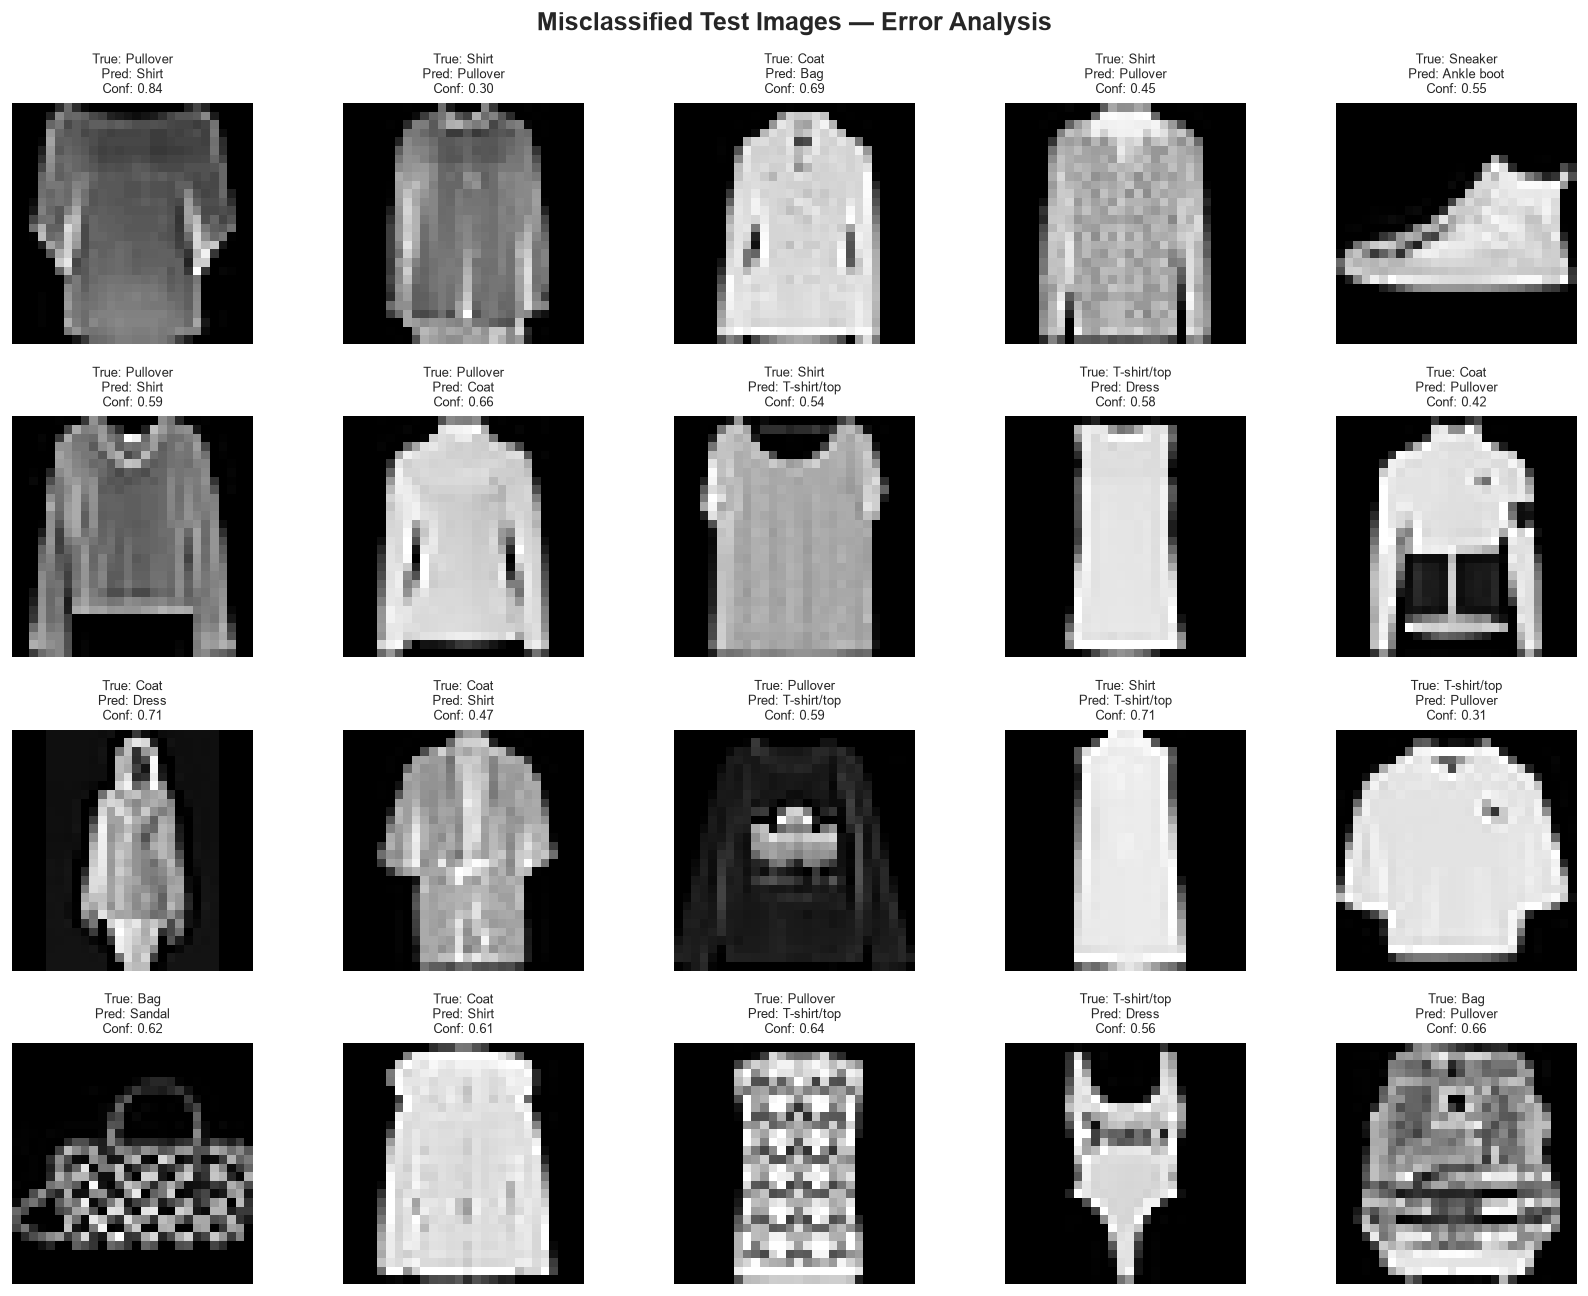

In [124]:
# Display the first 20 misclassified images for qualitative inspection
num_error_images = min(20, len(misclassified_indices))
fig, axes = plt.subplots(4, 5, figsize=(14, 11))
for plot_index, ax in enumerate(axes.flat):
    if plot_index < num_error_images:
        source_index = int(misclassified_indices[plot_index])
        ax.imshow(X_test[source_index].reshape(IMAGE_SIZE, IMAGE_SIZE), cmap="gray")
        ax.set_title(
            f"True: {CLASS_NAMES[int(y_test_true[source_index])]}\nPred: {CLASS_NAMES[int(y_test_pred[source_index])]}\nConf: {max_confidence[source_index]:.2f}",
            fontsize=8
        )
    ax.axis("off")
fig.suptitle("Misclassified Test Images — Error Analysis", fontsize=15, fontweight="bold")
fig.tight_layout()

In [125]:
# Save the misclassified image gallery
fig.savefig(IMAGES_DIR / "21_misclassified_gallery.png", bbox_inches="tight")
plt.show()

In [126]:
# Identify the most frequent class-to-class confusions, excluding the diagonal
confusion_pairs = []
for true_id in range(NUM_CLASSES):
    for pred_id in range(NUM_CLASSES):
        if true_id != pred_id and cm[true_id, pred_id] > 0:
            confusion_pairs.append({
                "true_class": CLASS_NAMES[true_id],
                "predicted_class": CLASS_NAMES[pred_id],
                "count": int(cm[true_id, pred_id]),
            })
top_confusions = pd.DataFrame(confusion_pairs).sort_values("count", ascending=False).head(15)
display(top_confusions)

,true_class,predicted_class,count
31,Shirt,T-shirt/top,184
20,Coat,Pullover,98
33,Shirt,Pullover,77
39,Sneaker,Ankle boot,56
35,Shirt,Coat,52
3,T-shirt/top,Shirt,51
10,Pullover,Shirt,50
9,Pullover,Coat,48
23,Coat,Shirt,42
15,Dress,Coat,30


In [127]:
# Plot the top confusions interactively
fig_confusions = px.bar(
    top_confusions.sort_values("count"), x="count", y="true_class", color="predicted_class",
    orientation="h", barmode="group", title="Most Frequent Class Confusions",
    labels={"count": "Misclassified images", "true_class": "True category", "predicted_class": "Predicted category"}
)
fig_confusions.update_layout(template="plotly_white", height=650)
fig_confusions.show()

In [128]:
# Export the interactive confusion analysis
fig_confusions.write_html(IMAGES_DIR / "22_top_class_confusions.html", include_plotlyjs="cdn")
top_confusions.to_csv(ARTIFACTS_DIR / "top_class_confusions.csv", index=False)

## 9. Multi-class ROC analysis and deeper diagnostics

In [129]:
# Binarize true labels for one-vs-rest ROC analysis
y_test_binary = label_binarize(y_test_true, classes=list(CLASS_NAMES.keys()))
print("Binarized target shape:", y_test_binary.shape)

Binarized target shape: (10000, 10)


In [130]:
# Compute one-vs-rest ROC curves and AUC values
roc_data = {}
for class_id in CLASS_NAMES:
    fpr, tpr, _ = roc_curve(y_test_binary[:, class_id], y_test_prob[:, class_id])
    roc_data[class_id] = {"fpr": fpr, "tpr": tpr, "auc": auc(fpr, tpr)}
macro_roc_auc = roc_auc_score(y_test_binary, y_test_prob, average="macro", multi_class="ovr")
print("Macro one-vs-rest ROC AUC:", round(float(macro_roc_auc), 4))

Macro one-vs-rest ROC AUC: 0.9929


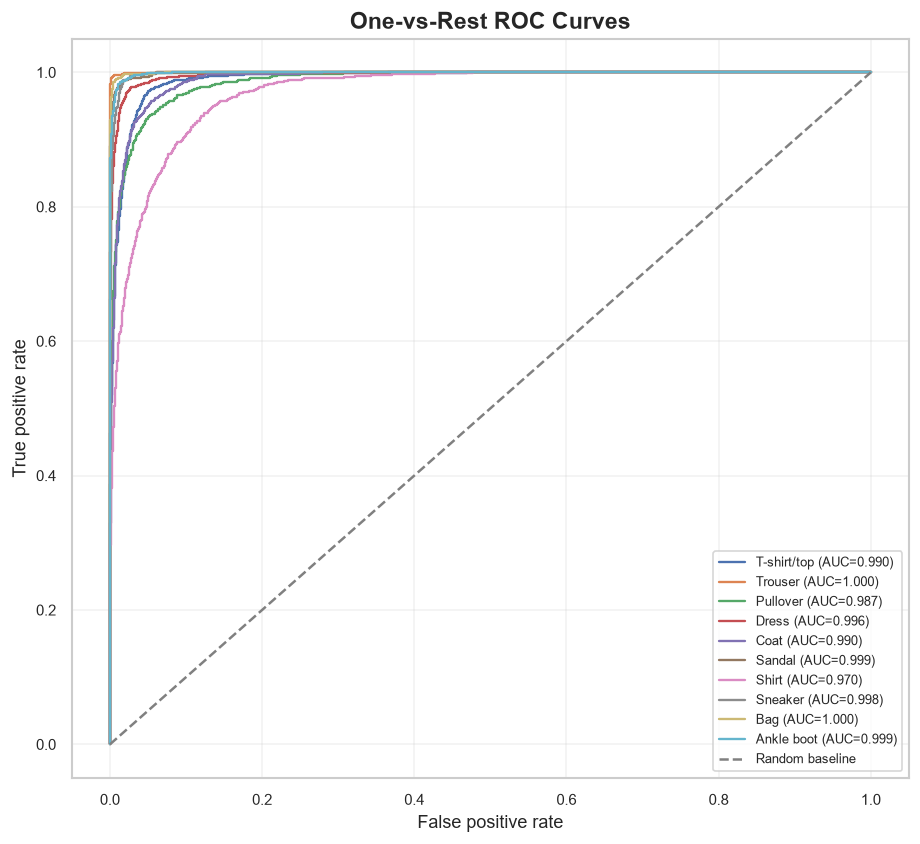

In [131]:
# Plot all one-vs-rest ROC curves
fig, ax = plt.subplots(figsize=(9, 8))
for class_id, values in roc_data.items():
    ax.plot(values["fpr"], values["tpr"], label=f"{CLASS_NAMES[class_id]} (AUC={values['auc']:.3f})", linewidth=1.4)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random baseline")
ax.set_title("One-vs-Rest ROC Curves", fontweight="bold")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.25)

In [132]:
# Save multi-class ROC figure
fig.savefig(IMAGES_DIR / "23_multiclass_roc_curves.png", bbox_inches="tight")
plt.show()

In [133]:
# Store per-class ROC AUC values
roc_auc_table = pd.DataFrame([
    {"class_id": class_id, "class_name": CLASS_NAMES[class_id], "roc_auc": values["auc"]}
    for class_id, values in roc_data.items()
])
roc_auc_table.to_csv(ARTIFACTS_DIR / "roc_auc_by_class.csv", index=False)
display(roc_auc_table.round(4))

,class_id,class_name,roc_auc
0,0,T-shirt/top,0.9904
1,1,Trouser,0.9998
2,2,Pullover,0.9870
3,3,Dress,0.9963
4,4,Coat,0.9897
5,5,Sandal,0.9989
6,6,Shirt,0.9701
7,7,Sneaker,0.9982
8,8,Bag,0.9995
9,9,Ankle boot,0.9990


In [134]:
# Add macro ROC AUC to the headline metrics
test_metrics["macro_ovr_roc_auc"] = float(macro_roc_auc)
print("Updated test metrics with macro ROC AUC.")

Updated test metrics with macro ROC AUC.


In [135]:
# Check accuracy for each true class from the confusion matrix diagonal
class_accuracy = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)
class_accuracy_df = pd.DataFrame({"class_name": class_labels, "accuracy": class_accuracy})
display(class_accuracy_df.sort_values("accuracy", ascending=False).round(4))

,class_name,accuracy
1,Trouser,0.986
8,Bag,0.978
9,Ankle boot,0.976
5,Sandal,0.942
3,Dress,0.922
7,Sneaker,0.919
0,T-shirt/top,0.906
2,Pullover,0.864
4,Coat,0.828
6,Shirt,0.644


In [136]:
# Compare train and validation performance at the best validation-loss epoch
generalization_gap = float(best_epoch_row["train_accuracy"] - best_epoch_row["val_accuracy"])
print(f"Accuracy generalization gap at best epoch: {generalization_gap:.4f}")

Accuracy generalization gap at best epoch: 0.0197


In [137]:
# Analyze mean confidence by correctness state
confidence_summary = confidence_df.groupby("correct")["confidence"].agg(["count", "mean", "median", "std"]).rename(index={True: "Correct", False: "Incorrect"})
display(confidence_summary.round(4))

,count,mean,median,std
correct,,,,
Incorrect,1035,0.6818,0.6663,0.1767
Correct,8965,0.9332,0.9927,0.1236


In [138]:
# Export confidence and class-accuracy diagnostics
confidence_df.to_csv(ARTIFACTS_DIR / "test_prediction_confidence.csv", index=False)
class_accuracy_df.to_csv(ARTIFACTS_DIR / "class_accuracy.csv", index=False)
confidence_summary.to_csv(ARTIFACTS_DIR / "confidence_summary.csv")

## 10. Model inspection and inference examples

In [139]:
# Visualize the first layer weight distribution
first_linear_layer = next(layer for layer in final_model.modules() if isinstance(layer, nn.Linear))
first_layer_weights = first_linear_layer.weight.detach().cpu().numpy()
print("First layer weight matrix:", first_layer_weights.shape)

First layer weight matrix: (384, 784)


Text(0, 0.5, 'Frequency')

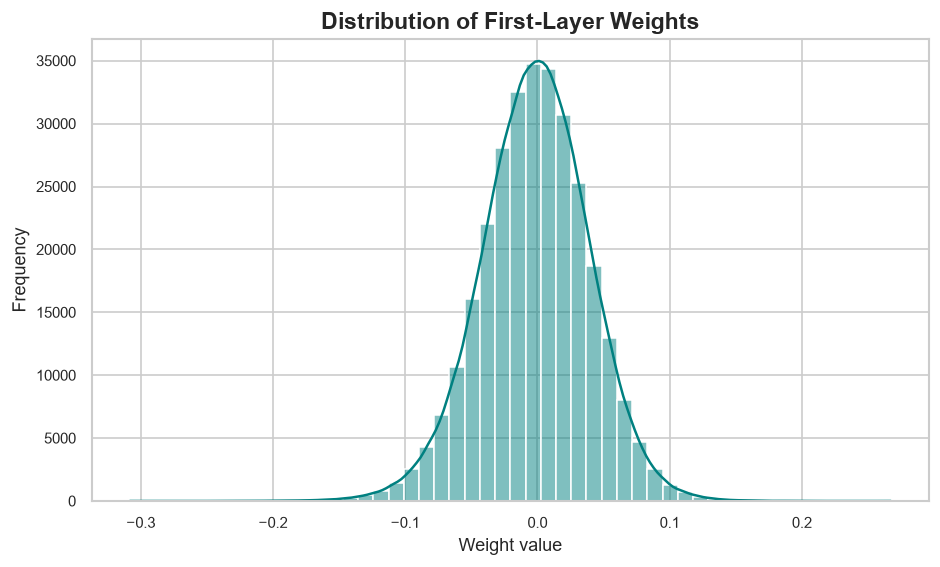

In [140]:
# Histogram of first-layer weights
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(first_layer_weights.ravel(), bins=50, kde=True, color="teal", ax=ax)
ax.set_title("Distribution of First-Layer Weights", fontweight="bold")
ax.set_xlabel("Weight value")
ax.set_ylabel("Frequency")

In [141]:
# Save first-layer weight distribution
fig.savefig(IMAGES_DIR / "24_first_layer_weight_distribution.png", bbox_inches="tight")
plt.show()

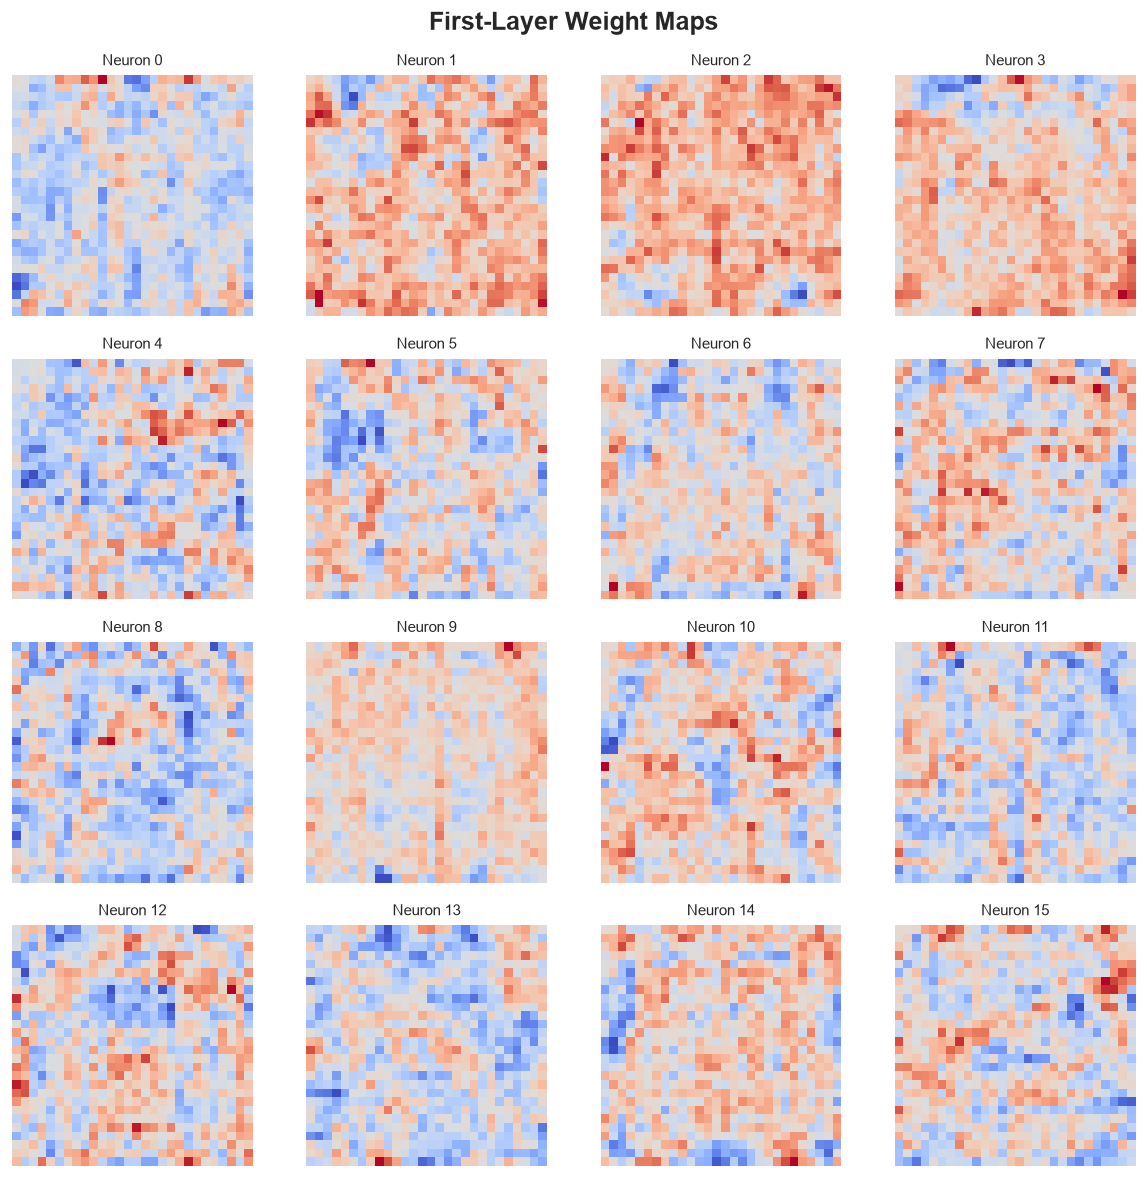

In [142]:
# Visualize a subset of first-layer neurons as 28 x 28 weight maps
num_neurons_to_show = min(16, first_layer_weights.shape[0])
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for neuron_index, ax in enumerate(axes.flat):
    if neuron_index < num_neurons_to_show:
        ax.imshow(first_layer_weights[neuron_index].reshape(IMAGE_SIZE, IMAGE_SIZE), cmap="coolwarm")
        ax.set_title(f"Neuron {neuron_index}", fontsize=9)
    ax.axis("off")
fig.suptitle("First-Layer Weight Maps", fontsize=15, fontweight="bold")
fig.tight_layout()

In [143]:
# Save first-layer weight maps
fig.savefig(IMAGES_DIR / "25_first_layer_weight_maps.png", bbox_inches="tight")
plt.show()

In [144]:
# Single-image prediction helper for flattened or 28 x 28 inputs
def predict_single_image(image_array, model=final_model):
    image_array = np.asarray(image_array, dtype=np.float32)
    if image_array.shape == (IMAGE_SIZE, IMAGE_SIZE):
        image_array = image_array.reshape(1, INPUT_DIM)
    elif image_array.shape == (INPUT_DIM,):
        image_array = image_array.reshape(1, INPUT_DIM)
    else:
        raise ValueError("Expected an image with shape (28, 28) or a flattened vector of length 784.")
    if image_array.max() > 1.0:
        image_array = image_array / 255.0
    tensor = torch.tensor(image_array, dtype=torch.float32, device=device)
    model.eval()
    with torch.inference_mode():
        probabilities = torch.softmax(model(tensor), dim=1).cpu().numpy()[0]
    predicted_id = int(np.argmax(probabilities))
    return {"class_id": predicted_id, "class_name": CLASS_NAMES[predicted_id],
            "confidence": float(probabilities[predicted_id]), "probabilities": probabilities}

In [145]:
# Run inference on one test image
sample_inference_index = 0
sample_image = X_test[sample_inference_index].reshape(IMAGE_SIZE, IMAGE_SIZE)
sample_prediction = predict_single_image(sample_image)
print(sample_prediction["class_name"], f"({sample_prediction['confidence']:.2%})")

T-shirt/top (95.57%)


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

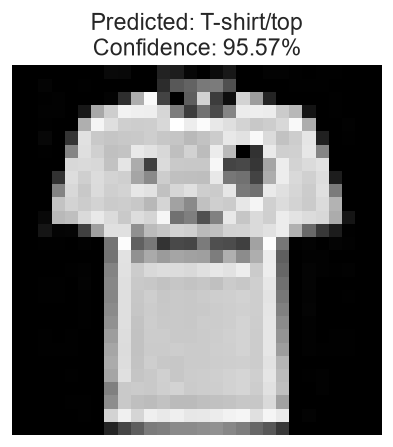

In [146]:
# Display the image and its predicted class
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(sample_image, cmap="gray")
ax.set_title(f"Predicted: {sample_prediction['class_name']}\nConfidence: {sample_prediction['confidence']:.2%}")
ax.axis("off")

In [147]:
# Save single-image inference example
fig.savefig(IMAGES_DIR / "26_single_image_inference.png", bbox_inches="tight")
plt.show()

In [148]:
# Plot the class probability vector for the selected image
probability_df = pd.DataFrame({"class_name": class_labels, "probability": sample_prediction["probabilities"]})
fig_probability = px.bar(probability_df, x="class_name", y="probability", color="probability",
                          title="Predicted Probability by Class", color_continuous_scale="Blues")
fig_probability.update_layout(template="plotly_white", yaxis_range=[0, 1], xaxis_tickangle=-30)
fig_probability.show()

In [149]:
# Export single-image probability chart
fig_probability.write_html(IMAGES_DIR / "27_single_image_probabilities.html", include_plotlyjs="cdn")

In [150]:
# Inspect a small inference batch and verify output shape
inference_batch = X_test[:32]
inference_tensor = torch.tensor(inference_batch, dtype=torch.float32, device=device)
final_model.eval()
with torch.inference_mode():
    inference_logits = final_model(inference_tensor)
    inference_probabilities = torch.softmax(inference_logits, dim=1)
print("Inference batch shape:", tuple(inference_probabilities.shape))

Inference batch shape: (32, 10)


In [151]:
# Top-3 predicted categories for the inference batch
top3_probabilities, top3_indices = torch.topk(inference_probabilities, k=3, dim=1)
top3_preview = pd.DataFrame({
    "sample": np.arange(len(inference_batch)),
    "top_1": [CLASS_NAMES[int(row[0])] for row in top3_indices.cpu().numpy()],
    "top_1_probability": top3_probabilities[:, 0].cpu().numpy(),
    "top_2": [CLASS_NAMES[int(row[1])] for row in top3_indices.cpu().numpy()],
    "top_3": [CLASS_NAMES[int(row[2])] for row in top3_indices.cpu().numpy()],
})
display(top3_preview.head(10))

,sample,top_1,top_1_probability,top_2,top_3
0,0,T-shirt/top,0.955736,Shirt,Pullover
1,1,Trouser,0.999970,Dress,Coat
2,2,Pullover,0.630021,Shirt,T-shirt/top
3,3,Pullover,0.557107,T-shirt/top,Shirt
4,4,Dress,0.605385,Coat,Pullover
5,5,Shirt,0.835846,T-shirt/top,Pullover
6,6,Bag,0.992849,Shirt,T-shirt/top
7,7,Pullover,0.298215,Dress,Shirt
8,8,Sandal,0.999996,Sneaker,Bag
9,9,T-shirt/top,0.994262,Shirt,Dress


## 11. Performance checks and export all deliverables

In [152]:
# Benchmark inference throughput on a fixed test subset
benchmark_size = min(2048, len(X_test))
benchmark_tensor = torch.tensor(X_test[:benchmark_size], dtype=torch.float32, device=device)
final_model.eval()
if device.type == "cuda":
    torch.cuda.synchronize()
benchmark_start = time.perf_counter()
with torch.inference_mode():
    _ = final_model(benchmark_tensor)
if device.type == "cuda":
    torch.cuda.synchronize()
benchmark_seconds = time.perf_counter() - benchmark_start
images_per_second = benchmark_size / max(benchmark_seconds, 1e-9)
print(f"Inference throughput: {images_per_second:,.1f} images/second ({device}).")

Inference throughput: 167,855.1 images/second (cpu).


In [153]:
# Save model checkpoint with architecture and label metadata
checkpoint_path = ARTIFACTS_DIR / "fashion_mnist_ann_checkpoint.pth"
checkpoint = {
    "model_state_dict": final_model.state_dict(),
    "architecture": {"input_dim": INPUT_DIM, "hidden_dims": best_config["hidden_dims"],
                     "num_classes": NUM_CLASSES, "dropout": best_config["dropout"]},
    "class_names": CLASS_NAMES,
    "random_seed": RANDOM_SEED,
    "test_accuracy": float(test_accuracy),
}
torch.save(checkpoint, checkpoint_path)
print(f"Checkpoint saved: artifacts/{checkpoint_path.name}")


Checkpoint saved: artifacts/fashion_mnist_ann_checkpoint.pth


In [154]:
# Save a lightweight state-dictionary file as well
torch.save(final_model.state_dict(), ARTIFACTS_DIR / "fashion_mnist_ann_state_dict.pth")

In [155]:
# Export a TorchScript inference artifact
scripted_model = torch.jit.trace(final_model.eval(), torch.zeros(1, INPUT_DIM, device=device))
scripted_model.save(str(ARTIFACTS_DIR / "fashion_mnist_ann_torchscript.pt"))
print("TorchScript model exported.")

TorchScript model exported.


In [156]:
# Persist the experiment configuration and environment metadata
experiment_metadata = {
    "project": "Fashion-MNIST ANN Classification",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "pytorch_version": torch.__version__,
    "device": str(device),
    "gpu_name": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
    "train_csv": str(TRAIN_CSV), "test_csv": str(TEST_CSV),
    "train_samples": int(len(train_dataset)), "validation_samples": int(len(val_dataset)),
    "test_samples": int(len(test_dataset)),
    "configuration": best_config,
    "random_seed": RANDOM_SEED,
}
with open(ARTIFACTS_DIR / "experiment_metadata.json", "w", encoding="utf-8") as file:
    json.dump(experiment_metadata, file, indent=2, default=str)

In [157]:
# Export headline metrics and training diagnostics
final_results = {**test_metrics, **training_summary, "inference_seconds": float(benchmark_seconds),
                 "inference_images_per_second": float(images_per_second)}
with open(ARTIFACTS_DIR / "final_metrics.json", "w", encoding="utf-8") as file:
    json.dump(final_results, file, indent=2)
pd.DataFrame([final_results]).to_csv(ARTIFACTS_DIR / "final_metrics.csv", index=False)
print("Final metrics exported.")

Final metrics exported.


In [158]:
# Save all test-set predictions and class probabilities
prediction_export = pd.DataFrame({
    "true_label": y_test_true, "true_class": [CLASS_NAMES[int(i)] for i in y_test_true],
    "predicted_label": y_test_pred, "predicted_class": [CLASS_NAMES[int(i)] for i in y_test_pred],
    "confidence": max_confidence, "correct": prediction_correct,
})
for class_id, class_name in CLASS_NAMES.items():
    safe_name = class_name.lower().replace("/", "_").replace(" ", "_")
    prediction_export[f"probability_{class_id}_{safe_name}"] = y_test_prob[:, class_id]
prediction_export.to_csv(ARTIFACTS_DIR / "test_predictions_with_probabilities.csv", index=False)
print("Prediction export rows:", len(prediction_export))

Prediction export rows: 10000


In [159]:
# Save class mapping separately for deployment consumers
with open(ARTIFACTS_DIR / "class_names.json", "w", encoding="utf-8") as file:
    json.dump(CLASS_NAMES, file, indent=2)

In [160]:
# Build a compact artifact inventory
artifact_inventory = []
for folder in [IMAGES_DIR, ARTIFACTS_DIR]:
    for file_path in sorted(folder.glob("*")):
        if file_path.is_file():
            artifact_inventory.append({
                "folder": folder.name, "file": file_path.name,
                "size_kb": round(file_path.stat().st_size / 1024, 2),
            })
inventory_df = pd.DataFrame(artifact_inventory)
display(inventory_df)

,folder,file,size_kb
0,images,01_class_distribution_matplotlib.png,85.02
1,images,01_derivative_and_tangent.png,68.36
2,images,01_examples_by_class.png,68.74
3,images,01_examples_by_class.svg,75.22
4,images,01_tensor_heatmap.png,35.20
...,...,...,...
166,artifacts,test_predictions.csv,477.22
167,artifacts,test_predictions_with_probabilities.csv,1620.49
168,artifacts,test_set_predictions.csv,360.76
169,artifacts,top_class_confusions.csv,0.30


In [161]:
# Export artifact inventory
inventory_df.to_csv(ARTIFACTS_DIR / "artifact_inventory.csv", index=False)

In [162]:
# Verify that the core deliverables exist
required_artifacts = [
    "fashion_mnist_ann_checkpoint.pth", "fashion_mnist_ann_state_dict.pth",
    "fashion_mnist_ann_torchscript.pt", "final_metrics.json",
    "classification_report.csv", "test_predictions_with_probabilities.csv",
]
missing_artifacts = [name for name in required_artifacts if not (ARTIFACTS_DIR / name).exists()]
assert not missing_artifacts, f"Missing artifacts: {missing_artifacts}"
print("Core artifact validation passed.")

Core artifact validation passed.


In [163]:
# Verify that key visualizations were saved
required_figures = [
    "01_examples_by_class.png", "02_class_distribution_matplotlib.png",
    "03_class_distribution_seaborn.png", "04_class_distribution_interactive.html",
    "16_confusion_matrix.png", "21_misclassified_gallery.png",
    "23_multiclass_roc_curves.png",
]
missing_figures = [name for name in required_figures if not (IMAGES_DIR / name).exists()]
print("Missing figures:", missing_figures)
assert not missing_figures, f"Missing figures: {missing_figures}"

Missing figures: []


In [164]:
# Print a concise executive summary of the experiment
print("=" * 64)
print("FASHION-MNIST ANN — FINAL EXPERIMENT SUMMARY")
print("=" * 64)
print(f"Device:                 {device}")
print(f"Training samples:       {len(train_dataset):,}")
print(f"Validation samples:     {len(val_dataset):,}")
print(f"Hold-out test samples:  {len(test_dataset):,}")
print(f"Trainable parameters:   {final_parameter_count:,}")
print(f"Test accuracy:          {test_accuracy:.2%}")
print(f"Macro F1:               {macro_f1:.4f}")
print(f"Macro OVR ROC AUC:      {macro_roc_auc:.4f}")
print(f"Training time:          {training_seconds:.1f} sec")
print(f"Inference throughput:   {images_per_second:,.1f} images/sec")
print("Images folder:          images/")
print("Artifacts folder:       artifacts/")
print("=" * 64)


FASHION-MNIST ANN — FINAL EXPERIMENT SUMMARY
Device:                 cpu
Training samples:       51,000
Validation samples:     9,000
Hold-out test samples:  10,000
Trainable parameters:   396,202
Test accuracy:          89.65%
Macro F1:               0.8951
Macro OVR ROC AUC:      0.9929
Training time:          49.2 sec
Inference throughput:   167,855.1 images/sec
Images folder:          images/
Artifacts folder:       artifacts/


## 12. Reproducibility notes and project deliverables

- The training CSV is split into training and validation partitions with stratification.
- The supplied test CSV is held out from Optuna search, early stopping, and model selection.
- Optuna is the primary hyperparameter optimization workflow and runs by default.
- A seeded TPE sampler explores model depth, width, activation, dropout, optimizer, learning rate, weight decay, batch size, and SGD momentum when applicable.
- Median pruning can stop underperforming trials early; the SQLite study database preserves experiment history.
- The best completed Optuna trial determines the final ANN configuration.
- Input pixels are normalized to `[0, 1]`; labels remain integer class IDs.
- GPU acceleration is selected automatically when CUDA is available. The same code remains compatible with CPU execution.
- Matplotlib and Seaborn figures are saved as PNG files; interactive Plotly/Optuna visualizations are saved as HTML files.

**Core Optuna outputs:** `artifacts/fashion_mnist_optuna.db`, `artifacts/optuna_trials.csv`, `artifacts/optuna_trial_summary.csv`, `artifacts/optuna_best_params.json`, and `artifacts/optuna_parameter_importance.csv`.

**Model deliverables:** trained PyTorch checkpoint, state dictionary, TorchScript model, test predictions, class-wise reports, experiment metadata, and visual error analysis.